# Project 01: Hệ đa agent hỗ trợ tư vấn bệnh tiểu đường

**Sinh viên:** Hoàng Hải, B23DCCN270, lớp nhóm 05. **Giảng viên:** PGS.TS Trần Đình Quế.

Notebook hiện thực sơ đồ trên bảng:

- **DB có sẵn → Deep Learning → Dự đoán, Phân loại**
- **web, book → tạo KB → KB + RAG**
- **Reinforcement Learning + Rule → Agent**
- Các nhánh hợp lại thành **tư vấn và trợ giúp**

Hệ thống chỉ phục vụ học tập, không thay thế chẩn đoán của bác sĩ. Chạy tuần tự từ đầu đến cuối bằng kernel **Python (project01)**.

## 0. Môi trường và cấu hình

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")  # tránh xung đột OpenMP giữa PyTorch và scikit-learn trên Windows
import json, re, time, uuid, unicodedata, warnings, platform
from collections import Counter, defaultdict
from dataclasses import dataclass, field, asdict
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import sklearn
import torch
from IPython.display import display, Markdown
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss, confusion_matrix, f1_score,
                             mean_absolute_error, precision_recall_curve, precision_score, r2_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import train_test_split
from torch import nn

warnings.filterwarnings("ignore")
SEED = 42
ROOT = Path.cwd()
DATA, RES = ROOT / "data", ROOT / "results"
FIG = RES / "figures"
FIG.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(1)  # máy 8 GB RAM, mạng nhỏ nên một luồng là đủ và ổn định hơn

BLUE, ORANGE, AQUA, YELLOW, VIOLET, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 170, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": .7,
                     "axes.axisbelow": True, "legend.frameon": False, "figure.facecolor": "white"})

def set_seed(seed):
    np.random.seed(seed); torch.manual_seed(seed)

def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f"{name}.png", bbox_inches="tight"); plt.show()

print("Python", platform.python_version(), "| PyTorch", torch.__version__, "| scikit-learn", sklearn.__version__,
      "| NumPy", np.__version__, "| pandas", pd.__version__)

Python 3.13.7 | PyTorch 2.15.0+cpu | scikit-learn 1.9.0 | NumPy 2.5.2 | pandas 3.0.5


## 1. DB có sẵn và dữ liệu đầu vào

Hệ thống dùng hai bộ dữ liệu có sẵn. Bộ 100.000 bản ghi có nhãn `diabetes`, dùng cho **phân loại**. Bộ 50.000 bản ghi có `Diabetes_Risk_Score` và `Diabetes_Risk`, dùng cho **dự đoán điểm nguy cơ**.

In [2]:
raw = pd.read_csv(DATA / "diabetes_100k.csv")
df = raw.drop_duplicates()
df = df[df.gender != "Other"].reset_index(drop=True)
print(f"Thô: {len(raw):,} dòng | sau khi bỏ trùng và gender=Other: {len(df):,} dòng | tỉ lệ dương: {df.diabetes.mean():.2%}")

train_df, tmp = train_test_split(df, test_size=.30, random_state=SEED, stratify=df.diabetes)
val_df, test_df = train_test_split(tmp, test_size=.50, random_state=SEED, stratify=tmp.diabetes)
print("train/val/test:", len(train_df), len(val_df), len(test_df))
df.head()

Thô: 100,000 dòng | sau khi bỏ trùng và gender=Other: 96,128 dòng | tỉ lệ dương: 8.82%
train/val/test: 67289 14419 14420


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


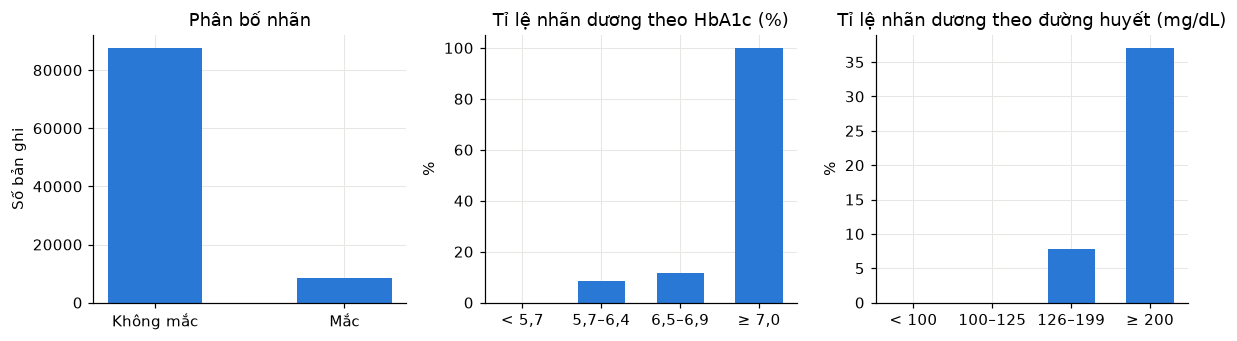

,Số dòng,% nhãn dương
HbA1c_level,,
"< 5,7",36258,0.0
"5,7–6,4",39770,8.3
"6,5–6,9",16854,11.5
"≥ 7,0",3246,100.0


In [3]:
bins_h = pd.cut(df.HbA1c_level, [0, 5.69, 6.49, 6.99, 20], labels=["< 5,7", "5,7–6,4", "6,5–6,9", "≥ 7,0"])
bins_g = pd.cut(df.blood_glucose_level, [0, 99, 125, 199, 1000], labels=["< 100", "100–125", "126–199", "≥ 200"])
tab_h = df.groupby(bins_h, observed=True).diabetes.agg(["count", "mean"])
tab_g = df.groupby(bins_g, observed=True).diabetes.agg(["count", "mean"])

fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
ax[0].bar(["Không mắc", "Mắc"], df.diabetes.value_counts().sort_index(), color=BLUE, width=.5)
ax[0].set_title("Phân bố nhãn"); ax[0].set_ylabel("Số bản ghi")
ax[1].bar(tab_h.index.astype(str), tab_h["mean"] * 100, color=BLUE, width=.6)
ax[1].set_title("Tỉ lệ nhãn dương theo HbA1c (%)"); ax[1].set_ylabel("%")
ax[2].bar(tab_g.index.astype(str), tab_g["mean"] * 100, color=BLUE, width=.6)
ax[2].set_title("Tỉ lệ nhãn dương theo đường huyết (mg/dL)"); ax[2].set_ylabel("%")
save(fig, "fig_eda")
tab_h.assign(mean=lambda t: (t["mean"] * 100).round(1)).rename(columns={"count": "Số dòng", "mean": "% nhãn dương"})

**Mâu thuẫn dữ liệu và tri thức.** Nhóm HbA1c 6,5–6,9% đã đạt ngưỡng đái tháo đường theo tài liệu y khoa, nhưng chỉ khoảng 11% trong nhóm này được gán nhãn dương. Mô hình học từ dữ liệu có thể báo nguy cơ thấp cho nhóm này, vì vậy hệ thống cần lớp **Rule** kiểm tra độc lập.

## 2. Deep Learning: phân loại với DiaNet

`DiaNet` là MLP có đầu vào `mask` cho biết xét nghiệm nào đã biết. Khi huấn luyện, HbA1c và đường huyết bị che ngẫu nhiên. Một mô hình duy nhất vì vậy xử lý được cả 4 trường hợp: chưa xét nghiệm, chỉ có HbA1c, chỉ có đường huyết và có cả hai. Đây là điều kiện cần cho tác tử RL ở Mục 5.

In [4]:
class MaskedMLP(nn.Module):
    """MLP dùng chung cho DiaNet và RiskNet; mỗi đầu ra là một head."""
    def __init__(self, d_in, heads, hidden=(128, 64, 32), dropout=.1):
        super().__init__()
        layers, d = [], d_in
        for width in hidden:
            layers += [nn.Linear(d, width), nn.ReLU(), nn.Dropout(dropout)]
            d = width
        self.body = nn.Sequential(*layers)
        self.heads = nn.ModuleDict({name: nn.Linear(d, n) for name, n in heads.items()})

    def forward(self, x):
        h = self.body(x)
        return {name: head(h) for name, head in self.heads.items()}

SMOKE = ["never", "No Info", "current", "former", "ever", "not current"]
STATS = dict(age=(train_df.age.mean(), train_df.age.std()), bmi=(train_df.bmi.mean(), train_df.bmi.std()),
             h=(train_df.HbA1c_level.mean(), train_df.HbA1c_level.std()),
             g=(train_df.blood_glucose_level.mean(), train_df.blood_glucose_level.std()))
SCEN = ["none", "hba1c", "glucose", "both"]  # chỉ số = bit0 HbA1c + 2*bit1 glucose
SCEN_VI = {"none": "Chưa xét nghiệm", "hba1c": "Chỉ HbA1c", "glucose": "Chỉ đường huyết", "both": "Đủ hai xét nghiệm"}

def z(v, key):
    return ((np.asarray(v, dtype=np.float64) - STATS[key][0]) / STATS[key][1]).astype(np.float32)

def dia_arrays(d):
    """Trả về đặc trưng nền, HbA1c và đường huyết đã chuẩn hóa."""
    base = np.column_stack([z(d.age, "age"), z(d.bmi, "bmi"), d.hypertension, d.heart_disease, (d.gender == "Male") * 1.0]
                           + [(d.smoking_history == s) * 1.0 for s in SMOKE]).astype(np.float32)
    return base, z(d.HbA1c_level, "h"), z(d.blood_glucose_level, "g")

def dia_input(base, h, g, mh, mg):
    return np.column_stack([base, h * mh, g * mg, mh, mg]).astype(np.float32)

def predict_dia(model, arrays, scen):
    base, h, g = arrays
    k = SCEN.index(scen)
    mh, mg = np.full(len(h), k & 1, np.float32), np.full(len(h), k >> 1, np.float32)
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.tensor(dia_input(base, h, g, mh, mg)))["cls"]).numpy().ravel()

A_train, A_val, A_test = dia_arrays(train_df), dia_arrays(val_df), dia_arrays(test_df)
y_train, y_val, y_test = train_df.diabetes.values, val_df.diabetes.values, test_df.diabetes.values
print("Số đặc trưng đầu vào của DiaNet:", A_val[0].shape[1] + 4)

Số đặc trưng đầu vào của DiaNet: 15


In [5]:
def train_dianet(seed, epochs=30, batch=1024, patience=5, p_mask=.5):
    set_seed(seed)
    base, h, g = (torch.tensor(a) for a in A_train)
    y = torch.tensor(y_train, dtype=torch.float32)
    model = MaskedMLP(base.shape[1] + 4, {"cls": 1})
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
    loss_fn = nn.BCEWithLogitsLoss()
    best, best_state, wait, history = -1, None, 0, []
    for epoch in range(epochs):
        model.train()
        perm, total = torch.randperm(len(y)), 0.
        for i in range(0, len(y), batch):
            b = perm[i:i + batch]
            mh = (torch.rand(len(b)) > p_mask).float()  # che ngẫu nhiên từng xét nghiệm
            mg = (torch.rand(len(b)) > p_mask).float()
            x = torch.cat([base[b], (h[b] * mh)[:, None], (g[b] * mg)[:, None], mh[:, None], mg[:, None]], 1)
            loss = loss_fn(model(x)["cls"].squeeze(1), y[b])
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(b)
        val_ap = np.mean([average_precision_score(y_val, predict_dia(model, A_val, s)) for s in SCEN])
        history.append((epoch + 1, total / len(y), val_ap))
        if val_ap > best + 1e-4:
            best, wait = val_ap, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history, columns=["epoch", "train_loss", "val_pr_auc"])

t0 = time.time()
runs = {s: train_dianet(s) for s in (42, 7, 2026)}
dianet, dia_hist = runs[42]
torch.save(dianet.state_dict(), RES / "dianet.pt")
print(f"Huấn luyện 3 seed trong {time.time() - t0:.0f} giây; seed 42 dừng ở epoch {len(dia_hist)}")
dia_hist.tail(3).round(4)

Huấn luyện 3 seed trong 50 giây; seed 42 dừng ở epoch 30


,epoch,train_loss,val_pr_auc
27,28,0.1522,0.6625
28,29,0.1513,0.6623
29,30,0.1496,0.6629


In [6]:
def ece(y, p, bins=10):
    edges = np.quantile(p, np.linspace(0, 1, bins + 1)); edges[-1] += 1e-9
    idx = np.clip(np.digitize(p, edges[1:-1]), 0, bins - 1)
    return sum((idx == b).mean() * abs(y[idx == b].mean() - p[idx == b].mean()) for b in range(bins) if (idx == b).any())

def best_f1_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr * rc / np.clip(pr + rc, 1e-9, None)
    return float(th[np.argmax(f1[:-1])])

def cls_metrics(y, p, t):
    yhat = p >= t
    return {"Accuracy": accuracy_score(y, yhat), "Precision": precision_score(y, yhat, zero_division=0), "Recall": recall_score(y, yhat),
            "F1": f1_score(y, yhat), "PR-AUC": average_precision_score(y, p), "ROC-AUC": roc_auc_score(y, p),
            "Brier": brier_score_loss(y, p), "ECE": ece(y, p)}

THRESH = {s: best_f1_threshold(y_val, predict_dia(dianet, A_val, s)) for s in SCEN}
P_val = {s: predict_dia(dianet, A_val, s) for s in SCEN}
P_test = {s: predict_dia(dianet, A_test, s) for s in SCEN}

def scen_matrix(d, s):
    X = pd.get_dummies(d[["gender", "smoking_history"]]).astype(float).reindex(columns=COLS_DUMMY, fill_value=0)
    X = X.assign(age=d.age, bmi=d.bmi, hyp=d.hypertension, heart=d.heart_disease)
    if s in ("hba1c", "both"): X["h"] = d.HbA1c_level
    if s in ("glucose", "both"): X["g"] = d.blood_glucose_level
    return X

COLS_DUMMY = pd.get_dummies(train_df[["gender", "smoking_history"]]).columns
rows = []
for s in SCEN:
    Xa, Xv, Xt = scen_matrix(train_df, s), scen_matrix(val_df, s), scen_matrix(test_df, s)
    mu, sd = Xa.mean(), Xa.std().replace(0, 1)
    baselines = {"Logistic Regression": LogisticRegression(max_iter=500).fit((Xa - mu) / sd, y_train),
                 "HistGradientBoosting": HistGradientBoostingClassifier(max_iter=200, random_state=SEED).fit(Xa, y_train)}
    for name, m in baselines.items():
        tv, tt = ((Xv - mu) / sd, (Xt - mu) / sd) if name.startswith("Log") else (Xv, Xt)
        t = best_f1_threshold(y_val, m.predict_proba(tv)[:, 1])
        rows.append({"Trường hợp": SCEN_VI[s], "Mô hình": name, **cls_metrics(y_test, m.predict_proba(tt)[:, 1], t)})
    rows.append({"Trường hợp": SCEN_VI[s], "Mô hình": "DiaNet (1 mô hình)", **cls_metrics(y_test, P_test[s], THRESH[s])})
dia_results = pd.DataFrame(rows)
dia_results.to_csv(RES / "dianet_results.csv", index=False)
dia_results.round(4)

,Trường hợp,Mô hình,Accuracy,Precision,Recall,F1,PR-AUC,ROC-AUC,Brier,ECE
0,Chưa xét nghiệm,Logistic Regression,0.8436,0.2925,0.5444,0.3806,0.3145,0.8317,0.0693,0.0059
1,Chưa xét nghiệm,HistGradientBoosting,0.8319,0.2809,0.5797,0.3785,0.3219,0.8350,0.0687,0.0031
2,Chưa xét nghiệm,DiaNet (1 mô hình),0.8563,0.3102,0.5130,0.3866,0.3260,0.8367,0.0684,0.0035
3,Chỉ HbA1c,Logistic Regression,0.9352,0.6482,0.5805,0.6125,0.7064,0.9346,0.0441,0.0058
4,Chỉ HbA1c,HistGradientBoosting,0.9472,0.7612,0.5860,0.6622,0.7633,0.9477,0.0370,0.0045
5,Chỉ HbA1c,DiaNet (1 mô hình),0.9460,0.7346,0.6088,0.6658,0.7691,0.9491,0.0367,0.0028
6,Chỉ đường huyết,Logistic Regression,0.9220,0.5668,0.4933,0.5275,0.6161,0.8999,0.0514,0.0094
7,Chỉ đường huyết,HistGradientBoosting,0.9338,0.6606,0.5137,0.5780,0.6869,0.9297,0.0444,0.0050
8,Chỉ đường huyết,DiaNet (1 mô hình),0.9364,0.7009,0.4878,0.5753,0.6776,0.9234,0.0451,0.0071
9,Đủ hai xét nghiệm,Logistic Regression,0.9569,0.8403,0.6324,0.7216,0.8124,0.9610,0.0339,0.0048


In [7]:
seed_rows = []
for sd_, (m, _) in runs.items():
    for s in SCEN:
        p = predict_dia(m, A_test, s)
        seed_rows.append({"seed": sd_, "Trường hợp": SCEN_VI[s], "PR-AUC": average_precision_score(y_test, p),
                          "F1": f1_score(y_test, p >= best_f1_threshold(y_val, predict_dia(m, A_val, s)))})
dia_seeds = pd.DataFrame(seed_rows).groupby("Trường hợp", sort=False)[["PR-AUC", "F1"]].agg(["mean", "std"]).round(4)
dia_seeds.to_csv(RES / "dianet_seeds.csv")
print("Ngưỡng F1 chọn trên validation:", {SCEN_VI[k]: round(v, 3) for k, v in THRESH.items()})
dia_seeds

Ngưỡng F1 chọn trên validation: {'Chưa xét nghiệm': 0.202, 'Chỉ HbA1c': 0.309, 'Chỉ đường huyết': 0.315, 'Đủ hai xét nghiệm': 0.397}


PR-AUC              F1        
                     mean     std    mean     std
Trường hợp                                       
Chưa xét nghiệm    0.3272  0.0012  0.3853  0.0019
Chỉ HbA1c          0.7677  0.0013  0.6659  0.0007
Chỉ đường huyết    0.6785  0.0015  0.5784  0.0043
Đủ hai xét nghiệm  0.8721  0.0007  0.7959  0.0044

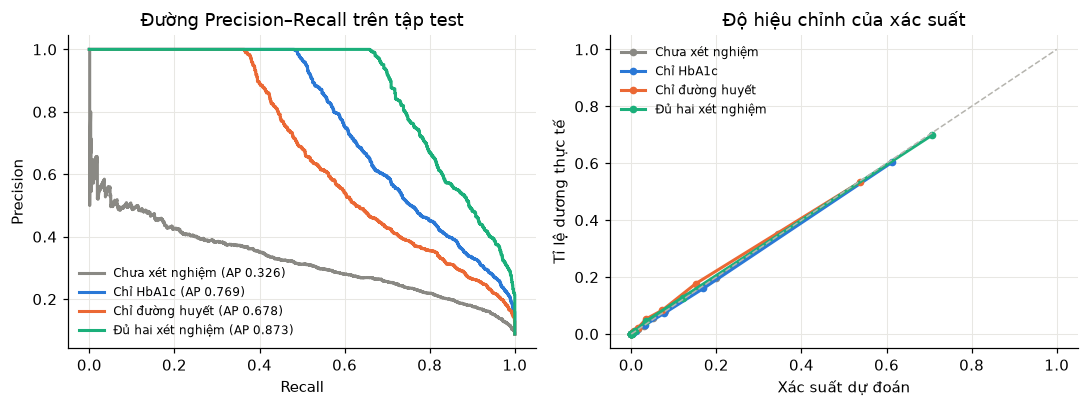

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for s, c in zip(SCEN, [GRAY, BLUE, ORANGE, AQUA]):
    pr, rc, _ = precision_recall_curve(y_test, P_test[s])
    ax[0].plot(rc, pr, color=c, lw=2, label=f"{SCEN_VI[s]} (AP {average_precision_score(y_test, P_test[s]):.3f})")
    q = pd.qcut(P_test[s], 10, duplicates="drop")
    cal = pd.DataFrame({"p": P_test[s], "y": y_test}).groupby(q, observed=True).mean()
    ax[1].plot(cal.p, cal.y, "-o", ms=4, lw=2, color=c, label=SCEN_VI[s])
ax[0].set(xlabel="Recall", ylabel="Precision", title="Đường Precision–Recall trên tập test"); ax[0].legend(fontsize=8)
ax[1].plot([0, 1], [0, 1], "--", color="#b5b4ae", lw=1)
ax[1].set(xlabel="Xác suất dự đoán", ylabel="Tỉ lệ dương thực tế", title="Độ hiệu chỉnh của xác suất"); ax[1].legend(fontsize=8)
save(fig, "fig_dianet")

## 3. Deep Learning: dự đoán với RiskNet

`RiskNet` học đa nhiệm trên bộ 50.000 bản ghi: **dự đoán** điểm nguy cơ 0–100 (hồi quy) và **phân loại** mức Low/Moderate/High. Đầu vào có mask cho từng đặc trưng vì người dùng thường không cung cấp đủ. Điểm này giúp agent ước lượng tác động tương đối của thay đổi lối sống; đây **không phải** xác suất mắc bệnh.

In [9]:
risk = pd.read_csv(DATA / "diabetes_risk_50k.csv")
ORD = {"Physical_Activity_Level": ["Low", "Moderate", "High"], "Diet_Quality": ["Poor", "Average", "Healthy"],
       "Sugar_Intake_Level": ["Low", "Moderate", "High"], "Stress_Level": ["Low", "Moderate", "High"],
       "Smoking_Status": ["Never", "Former", "Current"], "Alcohol_Consumption": ["Never", "Occasionally", "Frequently"]}
BIN = ["Family_History_Diabetes", "Hypertension", "Heart_Disease", "Fatty_Liver", "PCOS"]
NUM = ["Age", "BMI", "Waist_Circumference_cm", "HbA1c", "Fasting_Blood_Sugar", "Blood_Pressure_Systolic",
       "Exercise_Hours_Per_Week", "Sleep_Hours", "Insulin_Level", "Triglycerides", "HDL", "LDL", "Total_Cholesterol"]
RISK_COLS = NUM + list(ORD) + BIN
TIERS = ["Low", "Moderate", "High"]

def risk_frame(d):
    X = d[NUM].astype(float).copy()
    for c, levels in ORD.items():
        X[c] = d[c].map({v: i for i, v in enumerate(levels)}).astype(float)
    for c in BIN:
        X[c] = d[c].map({"No": 0., "Yes": 1.})
    return X[RISK_COLS]

R = risk_frame(risk)
yr, yc = risk.Diabetes_Risk_Score.values.astype(np.float32), risk.Diabetes_Risk.map({t: i for i, t in enumerate(TIERS)}).values
idx_tr, idx_tmp = train_test_split(np.arange(len(R)), test_size=.30, random_state=SEED, stratify=yc)
idx_va, idx_te = train_test_split(idx_tmp, test_size=.50, random_state=SEED, stratify=yc[idx_tmp])
R_mu, R_sd = R.iloc[idx_tr].mean(), R.iloc[idx_tr].std()

def risk_input(frame, keep=None):
    """Chuẩn hóa, điền 0 cho giá trị thiếu và nối mask đã biết/chưa biết."""
    Xz = ((frame - R_mu) / R_sd).astype(np.float32)
    M = Xz.notna().astype(np.float32).values
    if keep is not None:
        M = M * keep
    return np.hstack([np.nan_to_num(Xz.values) * M, M]).astype(np.float32)

def train_risknet(seed=SEED, epochs=80, batch=256, p_drop=.15, patience=10):
    set_seed(seed)
    Xz = ((R.iloc[idx_tr] - R_mu) / R_sd).astype(np.float32)
    V, M0 = torch.tensor(np.nan_to_num(Xz.values)), torch.tensor(Xz.notna().astype(np.float32).values)
    ys, yt = torch.tensor(yr[idx_tr] / 100), torch.tensor(yc[idx_tr])
    Xv, wv = torch.tensor(risk_input(R.iloc[idx_va])), yr[idx_va]
    model = MaskedMLP(V.shape[1] * 2, {"score": 1, "tier": 3}, hidden=(256, 128, 64), dropout=0.)
    w = torch.tensor(len(yt) / (3 * np.bincount(yc[idx_tr])), dtype=torch.float32)
    ce, hub = nn.CrossEntropyLoss(weight=w), nn.SmoothL1Loss(beta=.05)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
    best, state, wait = 1e9, None, 0
    for epoch in range(epochs):
        model.train(); perm = torch.randperm(len(ys))
        for i in range(0, len(ys), batch):
            b = perm[i:i + batch]
            M = M0[b] * (torch.rand_like(M0[b]) > p_drop).float()  # che ngẫu nhiên đặc trưng
            out = model(torch.cat([V[b] * M, M], 1))
            loss = 10 * hub(out["score"].squeeze(1), ys[b]) + .2 * ce(out["tier"], yt[b])
            opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            mae = np.abs(model(Xv)["score"].squeeze(1).numpy() * 100 - wv).mean()
        if mae < best - 1e-3:
            best, wait, state = mae, 0, {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(state)
    return model, epoch + 1

t0 = time.time()
risknet, ep = train_risknet()
torch.save(risknet.state_dict(), RES / "risknet.pt")
print(f"RiskNet dừng ở epoch {ep}, {time.time() - t0:.0f} giây")

RiskNet dừng ở epoch 77, 48 giây


In [10]:
def risk_predict(frame, keep=None):
    risknet.eval()
    with torch.no_grad():
        out = risknet(torch.tensor(risk_input(frame, keep)))
    return out["score"].squeeze(1).numpy() * 100, out["tier"].softmax(1).numpy()

LAB_COLS = ["HbA1c", "Fasting_Blood_Sugar", "Insulin_Level", "Triglycerides", "HDL", "LDL", "Total_Cholesterol"]
keep_nolab = np.array([0. if c in LAB_COLS else 1. for c in RISK_COLS], np.float32)
te = R.iloc[idx_te]
rows = []
for name, keep, frame in [("Đủ đặc trưng", None, te), ("Không có xét nghiệm", keep_nolab, te)]:
    s, t = risk_predict(frame, keep)
    rows.append({"Mô hình": "RiskNet", "Đầu vào": name, "MAE": mean_absolute_error(yr[idx_te], s), "RMSE": np.sqrt(((s - yr[idx_te]) ** 2).mean()),
                 "R²": r2_score(yr[idx_te], s), "Accuracy": accuracy_score(yc[idx_te], t.argmax(1)), "Macro-F1": f1_score(yc[idx_te], t.argmax(1), average="macro")})
for name, cols in [("Đủ đặc trưng", RISK_COLS), ("Không có xét nghiệm", [c for c in RISK_COLS if c not in LAB_COLS])]:
    reg = HistGradientBoostingRegressor(max_iter=300, random_state=SEED).fit(R.iloc[idx_tr][cols], yr[idx_tr])
    clf = HistGradientBoostingClassifier(max_iter=200, random_state=SEED, class_weight="balanced").fit(R.iloc[idx_tr][cols], yc[idx_tr])
    s, t = reg.predict(te[cols]), clf.predict(te[cols])
    rows.append({"Mô hình": "HistGradientBoosting", "Đầu vào": name, "MAE": mean_absolute_error(yr[idx_te], s), "RMSE": np.sqrt(((s - yr[idx_te]) ** 2).mean()),
                 "R²": r2_score(yr[idx_te], s), "Accuracy": accuracy_score(yc[idx_te], t), "Macro-F1": f1_score(yc[idx_te], t, average="macro")})
risk_results = pd.DataFrame(rows)
risk_results.to_csv(RES / "risknet_results.csv", index=False)
RISK_MAE = float(risk_results.MAE.iloc[0])
risk_results.round(4)

,Mô hình,Đầu vào,MAE,RMSE,R²,Accuracy,Macro-F1
0,RiskNet,Đủ đặc trưng,3.4151,4.3928,0.9218,0.8861,0.7305
1,RiskNet,Không có xét nghiệm,9.2639,11.5998,0.4546,0.6828,0.4695
2,HistGradientBoosting,Đủ đặc trưng,2.6748,3.4310,0.9523,0.9015,0.7646
3,HistGradientBoosting,Không có xét nghiệm,9.3839,11.2091,0.4907,0.7009,0.4754


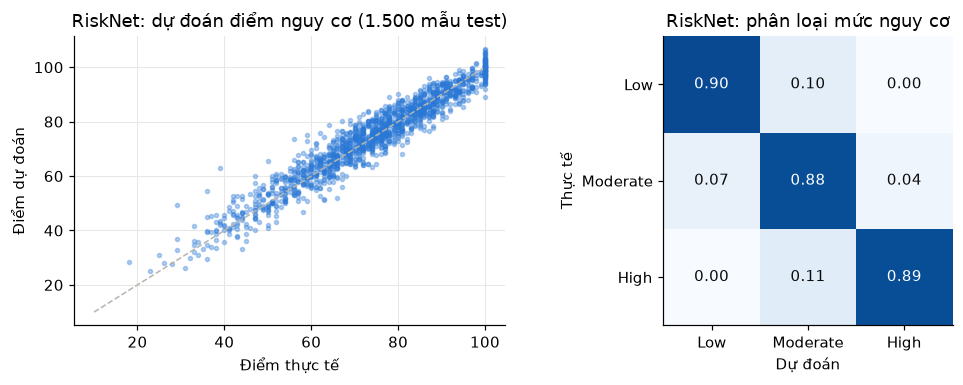

In [11]:
s_full, t_full = risk_predict(te)
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.6))
ax[0].scatter(yr[idx_te][:1500], s_full[:1500], s=7, color=BLUE, alpha=.35)
ax[0].plot([10, 100], [10, 100], "--", color="#b5b4ae", lw=1)
ax[0].set(xlabel="Điểm thực tế", ylabel="Điểm dự đoán", title="RiskNet: dự đoán điểm nguy cơ (1.500 mẫu test)")
cm = confusion_matrix(yc[idx_te], t_full.argmax(1), normalize="true")
im = ax[1].imshow(cm, cmap="Blues", vmin=0, vmax=1); ax[1].grid(False)
ax[1].set(xticks=range(3), yticks=range(3), xticklabels=TIERS, yticklabels=TIERS, xlabel="Dự đoán", ylabel="Thực tế", title="RiskNet: phân loại mức nguy cơ")
for i in range(3):
    for j in range(3):
        ax[1].text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="white" if cm[i, j] > .5 else "#0b0b0b")
save(fig, "fig_risknet")

In [12]:
def lever(col, low, high, n=3000):
    """Chênh lệch điểm trung bình khi chỉ đổi một đặc trưng trên mẫu test."""
    a, b = te.iloc[:n].copy(), te.iloc[:n].copy()
    a[col], b[col] = low, high
    return float((risk_predict(b)[0] - risk_predict(a)[0]).mean())
levers = pd.Series({"Vận động Low → High": lever("Physical_Activity_Level", 0., 2.), "Ăn uống Poor → Healthy": lever("Diet_Quality", 0., 2.),
                    "Hút thuốc Current → Never": lever("Smoking_Status", 2., 0.), "BMI 32 → 24": lever("BMI", 32., 24.)}, name="Đổi điểm TB")
levers.to_csv(RES / "risknet_levers.csv")
levers.round(2).to_frame()

,Đổi điểm TB
Vận động Low → High,-6.26
Ăn uống Poor → Healthy,-4.91
Hút thuốc Current → Never,-4.76
BMI 32 → 24,-4.90


## 4. KB: Knowledge Graph và RAG

KB được tạo từ **web và book**: các trang NIDDK, WHO, Diabetes UK và sách *Physical Activity Guidelines for Americans, 2nd edition*. Mỗi ghi chú lưu nguồn, URL, ngày truy cập và vị trí trong sách. Ngưỡng xét nghiệm được tách thành bảng có cấu trúc để Rule đối chiếu bằng code.

In [13]:
docs = json.loads((DATA / "kb_documents.json").read_text(encoding="utf-8"))
DOC = {d["doc_id"]: d for d in docs}
triples = pd.read_csv(DATA / "kb_triples.csv")
thresholds = pd.read_csv(DATA / "kb_thresholds.csv")

G = nx.MultiDiGraph()
for t in triples.itertuples():
    G.add_node(t.subject, kind=t.subject_type); G.add_node(t.object, kind=t.object_type)
    G.add_edge(t.subject, t.object, relation=t.relation, doc_id=t.doc_id)

kinds = Counter(nx.get_node_attributes(G, "kind").values())
kb_stats = {"Ghi chú (passage)": len(docs), "Ghi chú từ web": sum(d["source_type"] == "web" for d in docs),
            "Ghi chú từ sách": sum(d["source_type"] == "book" for d in docs), "URL nguồn khác nhau": len({d["url"] for d in docs}),
            "Thực thể": G.number_of_nodes(), "Quan hệ": G.number_of_edges(), "Loại quan hệ": triples.relation.nunique(),
            "Loại thực thể": len(kinds), "Ngưỡng có cấu trúc": len(thresholds)}
assert G.number_of_nodes() >= 50 and G.number_of_edges() >= 100 and triples.relation.nunique() >= 5 and len(kinds) >= 3
pd.Series(kb_stats, name="Số lượng").to_csv(RES / "kb_stats.csv")
display(pd.Series(kb_stats, name="Số lượng").to_frame())
print(dict(kinds.most_common()))
thresholds

,Số lượng
Ghi chú (passage),78
Ghi chú từ web,72
Ghi chú từ sách,6
URL nguồn khác nhau,20
Thực thể,156
Quan hệ,183
Loại quan hệ,58
Loại thực thể,10
Ngưỡng có cấu trúc,11


{'Concept': 49, 'Symptom': 16, 'Complication': 15, 'RiskFactor': 15, 'Test': 13, 'Lifestyle': 12, 'Disease': 11, 'Drug': 10, 'DrugClass': 8, 'Feature': 7}


,test,category,lower,upper,unit,doc_id
0,HbA1c,Bình thường,NaN,5.7,%,N01
1,HbA1c,Tiền đái tháo đường,5.7,6.5,%,N01
2,HbA1c,Ngưỡng đái tháo đường,6.5,NaN,%,N01
3,Đường huyết đói,Bình thường,NaN,100.0,mg/dL,N02
4,Đường huyết đói,Tiền đái tháo đường,100.0,126.0,mg/dL,N02
5,Đường huyết đói,Ngưỡng đái tháo đường,126.0,NaN,mg/dL,N02
6,OGTT 2 giờ,Bình thường,NaN,140.0,mg/dL,N03
7,OGTT 2 giờ,Tiền đái tháo đường,140.0,200.0,mg/dL,N03
8,OGTT 2 giờ,Ngưỡng đái tháo đường,200.0,NaN,mg/dL,N03
9,Đường huyết ngẫu nhiên,Ngưỡng đái tháo đường (khi có triệu chứng),200.0,NaN,mg/dL,N04


Máy thực nghiệm không chạy Neo4j, nên đồ thị được truy vấn bằng NetworkX. Năm truy vấn dưới đây viết kèm Cypher tương đương; tệp `results/kb_import.cypher` dùng để nạp đồ thị vào Neo4j khi cần. **Các câu Cypher chưa được chạy trên Neo4j.**

In [14]:
def out_of(node, relation=None):
    return [(node, e["relation"], o, e["doc_id"]) for _, o, e in G.out_edges(node, data=True) if relation in (None, e["relation"])]

def into(node, relation=None):
    return [(s, e["relation"], node, e["doc_id"]) for s, _, e in G.in_edges(node, data=True) if relation in (None, e["relation"])]

cypher_queries = [
 ("Triệu chứng của hạ đường huyết", "MATCH (:Entity {name:'Hạ đường huyết'})-[:có_thể_có_triệu_chứng]->(s) RETURN s.name",
  [o for _, _, o, _ in out_of("Hạ đường huyết", "có_thể_có_triệu_chứng")]),
 ("Xét nghiệm chẩn đoán đái tháo đường", "MATCH (:Entity {name:'Đái tháo đường'})-[:chẩn_đoán_bằng]->(t) RETURN t.name",
  [o for _, _, o, _ in out_of("Đái tháo đường", "chẩn_đoán_bằng")]),
 ("Lối sống giúp phòng type 2", "MATCH (l)-[:giúp_phòng_hoặc_trì_hoãn]->(:Entity {name:'Type 2'}) RETURN l.name",
  [s for s, _, _, _ in into("Type 2", "giúp_phòng_hoặc_trì_hoãn")]),
 ("Biến chứng hút thuốc làm tăng nguy cơ", "MATCH (:Entity {name:'Hút thuốc'})-[:tăng_nguy_cơ]->(c) RETURN c.name",
  [o for _, _, o, _ in out_of("Hút thuốc", "tăng_nguy_cơ")]),
 ("Cột dữ liệu nối với thực thể tri thức", "MATCH (f:Feature)-[:ánh_xạ_tới]->(e) RETURN f.name, e.name",
  [f"{s} → {o}" for s, _, o in triples.loc[triples.relation == "ánh_xạ_tới", ["subject", "relation", "object"]].values]),
]
for title, cy, ans in cypher_queries:
    print(f"• {title}\n  {cy}\n  → {ans}\n")

esc = lambda s: str(s).replace("\\", "\\\\").replace("'", "\\'")
with open(RES / "kb_import.cypher", "w", encoding="utf-8") as fh:
    for n, a in G.nodes(data=True):
        fh.write(f"MERGE (:Entity:{a['kind']} {{name:'{esc(n)}'}});\n")
    for t in triples.itertuples():
        fh.write(f"MATCH (a:Entity {{name:'{esc(t.subject)}'}}),(b:Entity {{name:'{esc(t.object)}'}}) MERGE (a)-[:`{t.relation}` {{doc_id:'{t.doc_id}'}}]->(b);\n")

• Triệu chứng của hạ đường huyết
  MATCH (:Entity {name:'Hạ đường huyết'})-[:có_thể_có_triệu_chứng]->(s) RETURN s.name
  → ['Run', 'Chóng mặt', 'Lú lẫn', 'Tim đập nhanh', 'Đau đầu', 'Mất ý thức', 'Co giật']

• Xét nghiệm chẩn đoán đái tháo đường
  MATCH (:Entity {name:'Đái tháo đường'})-[:chẩn_đoán_bằng]->(t) RETURN t.name
  → ['HbA1c', 'Đường huyết đói', 'OGTT', 'Đường huyết ngẫu nhiên']

• Lối sống giúp phòng type 2
  MATCH (l)-[:giúp_phòng_hoặc_trì_hoãn]->(:Entity {name:'Type 2'}) RETURN l.name
  → ['Hoạt động thể lực', 'Quản lý cân nặng', 'Giảm 5–7% cân nặng', 'Giảm đồ uống có đường', 'Giảm khẩu phần', 'Giữ cân nặng bình thường', 'Tránh thuốc lá']

• Biến chứng hút thuốc làm tăng nguy cơ
  MATCH (:Entity {name:'Hút thuốc'})-[:tăng_nguy_cơ]->(c) RETURN c.name
  → ['Bệnh tim', 'Đột quỵ', 'Bệnh thận do diabetes', 'Bệnh mắt do diabetes', 'Tổn thương thần kinh']

• Cột dữ liệu nối với thực thể tri thức
  MATCH (f:Feature)-[:ánh_xạ_tới]->(e) RETURN f.name, e.name
  → ['age → Tuổi từ 35',

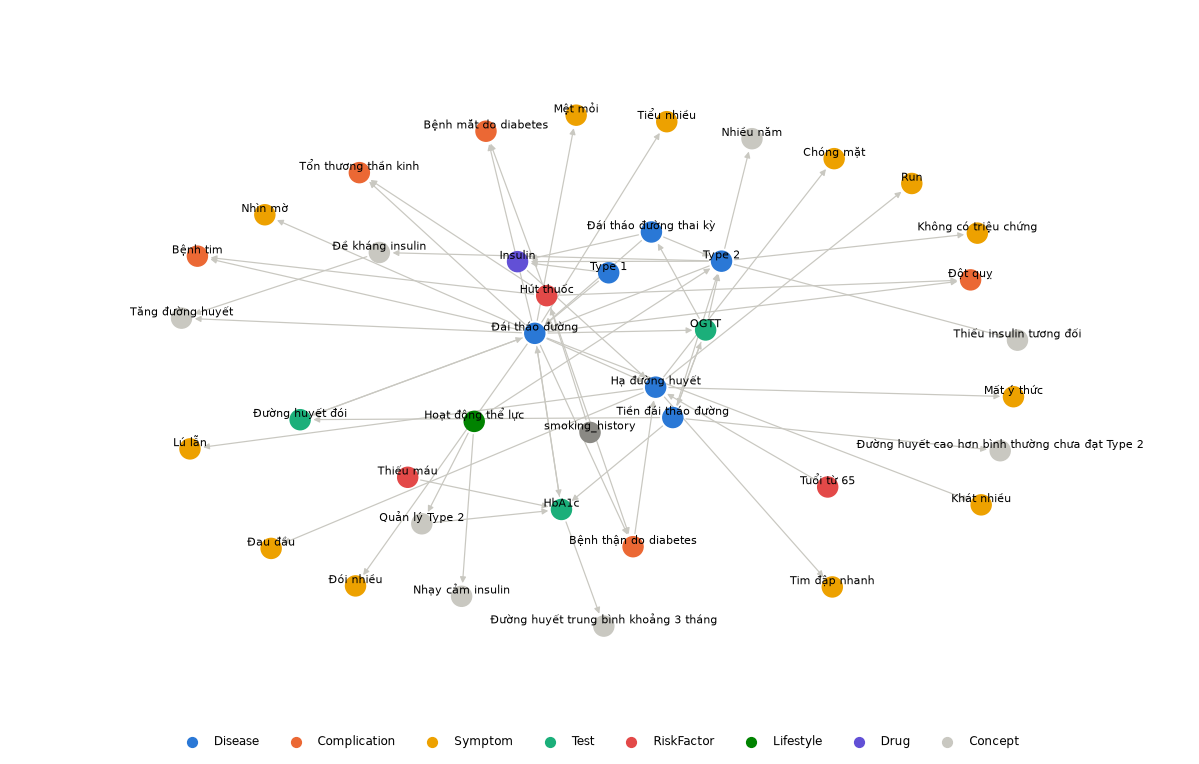

In [15]:
center = ["Đái tháo đường", "Tiền đái tháo đường", "Type 2", "Hạ đường huyết", "HbA1c", "Hút thuốc", "Hoạt động thể lực"]
nodes = set(center)
for c in center:
    nodes |= {o for _, _, o, _ in out_of(c)[:6]} | {s for s, _, _, _ in into(c)[:3]}
H = nx.DiGraph(G.subgraph(nodes))
pos = nx.spring_layout(H, k=1.5, seed=3, iterations=120)
palette = {"Disease": BLUE, "Complication": ORANGE, "Symptom": YELLOW, "Test": AQUA, "Drug": VIOLET, "DrugClass": VIOLET,
           "RiskFactor": "#e34948", "Lifestyle": "#008300", "Feature": GRAY, "Concept": "#c9c8c1"}
fig, ax = plt.subplots(figsize=(11, 7)); ax.axis("off"); ax.grid(False); ax.margins(.14)
nx.draw_networkx_edges(H, pos, ax=ax, edge_color="#c9c8c1", arrows=True, arrowsize=8, width=.8)
nx.draw_networkx_nodes(H, pos, ax=ax, node_size=170, node_color=[palette[G.nodes[n]["kind"]] for n in H])
nx.draw_networkx_labels(H, pos, ax=ax, font_size=7.5, verticalalignment="bottom")
for k in ["Disease", "Complication", "Symptom", "Test", "RiskFactor", "Lifestyle", "Drug", "Concept"]:
    ax.scatter([], [], color=palette[k], label=k, s=40)
ax.legend(ncol=8, loc="lower center", fontsize=8, bbox_to_anchor=(.5, -.04))
save(fig, "fig_kg")

### RAG: truy xuất lai

Ba bộ truy xuất cùng chạy trên 78 ghi chú:

- **Lexical:** TF-IDF từ và cụm hai từ.
- **Vector:** TF-IDF ký tự, giảm chiều bằng LSA thành vector 64 chiều, so khớp cosine.
- **KG:** liên kết thực thể trong câu hỏi, chấm điểm ghi chú theo quan hệ của các thực thể đó.

Xếp hạng cuối dùng **Reciprocal Rank Fusion (RRF)**. Máy 8 GB RAM không nạp ổn định model embedding Transformer, nên vector LSA được dùng thay thế.

In [16]:
SYN = [("tieu duong", "dai thao duong"), ("tuyp", "type"), ("typ ", "type "), ("tip ", "type "), ("a1c", "hba1c"), ("hbhba1c", "hba1c"),
       ("tut duong", "ha duong huyet"), ("tut duong huyet", "ha duong huyet"), ("tap the duc", "van dong hoat dong the luc"),
       ("nuoc ngot", "do uong co duong"), ("thuoc la", "hut thuoc"), ("mang bau", "mang thai thai ky"), ("bau", "thai ky"),
       ("ngat", "mat y thuc"), ("glucose", "duong huyet glucose"), ("xu ly", "xu tri")]

def norm(s):
    s = str(s).lower().replace("đ", "d")
    return "".join(c for c in unicodedata.normalize("NFD", s) if unicodedata.category(c) != "Mn")

def expand(q):
    s = norm(q)
    for a, b in SYN:
        s = s.replace(a, b)
    return s

ENTITY_KEYS = {norm(n).replace("diabetes", "dai thao duong"): n for n in G.nodes if len(n) >= 3 and G.nodes[n]["kind"] != "Feature"}

def link_entities(q):
    s = expand(q)
    found = [n for k, n in ENTITY_KEYS.items() if re.search(rf"(?<!\w){re.escape(k)}(?!\w)", s)]
    return sorted(set(found), key=len, reverse=True)

class HybridRetriever:
    def __init__(self, docs, dims=64):
        self.docs = docs
        self.ids = [d["doc_id"] for d in docs]
        text = [expand(d["title"] + ". " + d["text"]) for d in docs]
        self.word = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
        self.W = self.word.fit_transform(text)
        self.char = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True)
        C = self.char.fit_transform(text)
        self.svd = TruncatedSVD(dims, random_state=SEED).fit(C)
        self.V = self._unit(self.svd.transform(C))
        self.edge_docs = defaultdict(set)
        for t in triples.itertuples():
            self.edge_docs[t.subject].add(t.doc_id); self.edge_docs[t.object].add(t.doc_id)

    @staticmethod
    def _unit(X):
        return X / np.clip(np.linalg.norm(X, axis=1, keepdims=True), 1e-9, None)

    def lexical(self, q):
        return (self.W @ self.word.transform([expand(q)]).T).toarray().ravel()

    def vector(self, q):
        return self.V @ self._unit(self.svd.transform(self.char.transform([expand(q)])))[0]

    def kg(self, q):
        ents = link_entities(q)
        score = np.zeros(len(self.ids))
        for e in ents:
            for i, d in enumerate(self.ids):
                score[i] += d in self.edge_docs[e]
        return score / max(1, len(ents))

    def search(self, q, k=5, mode="hybrid", rrf_k=30):
        scores = {"lexical": self.lexical(q), "vector": self.vector(q), "kg": self.kg(q)}
        if mode != "hybrid":
            rank = np.argsort(-scores[mode], kind="stable")
            return [(self.ids[i], float(scores[mode][i])) for i in rank[:k] if scores[mode][i] > 0]
        fused = np.zeros(len(self.ids))
        for name, weight in (("lexical", 1.0), ("vector", .7), ("kg", .5)):
            order = np.argsort(-scores[name], kind="stable")
            for r, i in enumerate(order):
                if scores[name][i] > 0:
                    fused[i] += weight / (rrf_k + r + 1)
        rank = np.argsort(-fused, kind="stable")
        return [(self.ids[i], float(scores["lexical"][i])) for i in rank[:k] if fused[i] > 0]

retriever = HybridRetriever(docs)
np.savez_compressed(RES / "kb_vectors.npz", vectors=retriever.V.astype(np.float32), ids=np.array(retriever.ids))
print("Vector store:", retriever.V.shape, "| Thực thể trong câu mẫu:", link_entities("Tiểu đường tuýp 2 có cần xét nghiệm HbA1c không?"))
for doc_id, score in retriever.search("tôi bị tụt đường huyết thì xử lý thế nào", k=3):
    print(doc_id, round(score, 3), DOC[doc_id]["title"])

Vector store: (78, 64) | Thực thể trong câu mẫu: ['Đái tháo đường', 'Type 2', 'HbA1c']
N17 0.274 Ai dễ bị hạ đường huyết
N19 0.217 Hạ đường huyết nặng
N15 0.156 Hạ đường huyết là gì


In [17]:
eval_sets = json.loads((DATA / "eval_sets.json").read_text(encoding="utf-8"))
QRELS = eval_sets["retrieval_queries"]

def retrieval_eval(mode, k):
    rec, hit, rr, lat = [], [], [], []
    for item in QRELS:
        t = time.perf_counter()
        got = [d for d, _ in retriever.search(item["q"], k=k, mode=mode)]
        lat.append((time.perf_counter() - t) * 1000)
        gold = set(item["gold"])
        rec.append(len(gold & set(got)) / len(gold)); hit.append(bool(gold & set(got)))
        rr.append(next((1 / (i + 1) for i, d in enumerate(got) if d in gold), 0))
    return {"Chế độ": mode, "k": k, "Recall@k": np.mean(rec), "Hit@k": np.mean(hit), "MRR": np.mean(rr), "Trễ TB (ms)": np.mean(lat)}

ret_results = pd.DataFrame([retrieval_eval(m, k) for m in ("lexical", "vector", "kg", "hybrid") for k in (1, 3, 5)])
ret_results.to_csv(RES / "retrieval_results.csv", index=False)
print(len(QRELS), "câu hỏi có gold")
ret_results.pivot(index="Chế độ", columns="k", values=["Recall@k", "MRR"]).round(3)

40 câu hỏi có gold


Recall@k                  MRR              
k              1      3      5      1      3      5
Chế độ                                             
hybrid     0.538  0.796  0.904  0.675  0.754  0.765
kg         0.112  0.225  0.342  0.125  0.183  0.223
lexical    0.571  0.800  0.888  0.700  0.775  0.794
vector     0.496  0.746  0.842  0.650  0.721  0.733

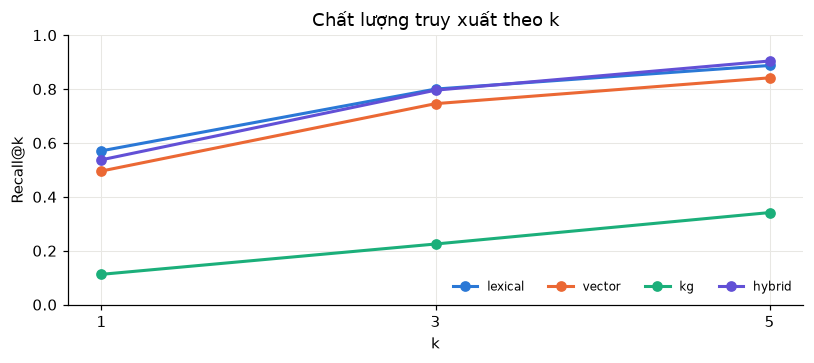

In [18]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
modes = ["lexical", "vector", "kg", "hybrid"]
for m, c in zip(modes, [BLUE, ORANGE, AQUA, VIOLET]):
    r = ret_results[ret_results["Chế độ"] == m]
    ax.plot(r.k, r["Recall@k"], "-o", color=c, lw=2, ms=6, label=m)
ax.set(xlabel="k", ylabel="Recall@k", xticks=[1, 3, 5], ylim=(0, 1), title="Chất lượng truy xuất theo k")
ax.legend(ncol=4, fontsize=8, loc="lower right")
save(fig, "fig_retrieval")

## 5. Reinforcement Learning + Rule: Policy Agent

Agent phải quyết định **bước tiếp theo** sau khi có dự đoán: yêu cầu thêm xét nghiệm hay dừng để đưa ra khuyến nghị. Xét nghiệm có chi phí; bỏ sót người mắc bệnh bị phạt nặng. Đây là bài toán ra quyết định tuần tự nên phù hợp với RL.

| Thành phần MDP | Định nghĩa |
|---|---|
| Trạng thái | (xét nghiệm đã biết, nhóm xác suất của DiaNet): 4 × 6 = 24 trạng thái |
| Hành động | `ORDER_HBA1C`, `ORDER_GLUCOSE`, `ADVISE_ROUTINE`, `REFER_DOCTOR` |
| Chuyển trạng thái | Xét nghiệm mở ra giá trị thật của bệnh nhân, DiaNet tính lại xác suất |
| Phần thưởng | HbA1c −1, đường huyết −0,5; chuyển khám đúng +20, sai −4; tư vấn thường đúng +2, bỏ sót −50 |

Các mức phần thưởng là **giả định thiết kế** của đồ án, không phải chi phí y tế thực. Q-learning học trên tập validation (DiaNet chưa thấy khi học trọng số) và đánh giá trên tập test.

In [19]:
ACTIONS = ["ORDER_HBA1C", "ORDER_GLUCOSE", "ADVISE_ROUTINE", "REFER_DOCTOR"]
A_H, A_G, A_ROUTINE, A_REFER = range(4)
EDGES = [.02, .05, .10, .30, .60]
NB = len(EDGES) + 1
N_STATES = 4 * NB
REWARD = dict(cost_h=1., cost_g=.5, tp=20., fn=-50., tn=2., fp=-4.)

def state_bins(P):
    return np.column_stack([np.digitize(P[s], EDGES) for s in SCEN])  # cột = known 0..3

def legal(known):
    return [a for a in range(4) if not (a == A_H and known & 1) and not (a == A_G and known & 2)]

def terminal_reward(a, y, R):
    if a == A_REFER:
        return R["tp"] if y else R["fp"]
    return R["fn"] if y else R["tn"]

def train_q(B, y, seed, episodes=150_000, gamma=1., R=REWARD, eps_end=.05, log_every=5000):
    rng = np.random.default_rng(seed)
    Q, N = np.zeros((N_STATES, 4)), np.zeros((N_STATES, 4))
    for s in range(N_STATES):
        for a in range(4):
            if a not in legal(s // NB):
                Q[s, a] = -1e9
    Bl, yl = B.tolist(), y.tolist()
    patients = rng.integers(0, len(yl), episodes).tolist()
    explore = rng.random((episodes, 3)).tolist()
    picks = rng.integers(0, 12, (episodes, 3)).tolist()
    curve, acc = [], 0.
    for ep, i in enumerate(patients):
        eps = max(eps_end, 1 - ep / (.6 * episodes))
        known, total = 0, 0.
        for step in range(3):
            s = known * NB + Bl[i][known]
            acts = legal(known)
            a = acts[picks[ep][step] % len(acts)] if explore[ep][step] < eps else int(np.argmax(Q[s]))
            if a in (A_H, A_G):
                r = -R["cost_h"] if a == A_H else -R["cost_g"]
                known |= 1 if a == A_H else 2
                s2 = known * NB + Bl[i][known]
                target = r + gamma * Q[s2].max()
            else:
                r = terminal_reward(a, yl[i], R)
                target = r
            N[s, a] += 1
            Q[s, a] += max(.002, 1 / (1 + N[s, a]) ** .7) * (target - Q[s, a])
            total += r
            if a >= A_ROUTINE:
                break
        acc += total
        if (ep + 1) % log_every == 0:
            curve.append((ep + 1, acc / log_every)); acc = 0.
    return Q, N, np.array(curve)

B_val, B_test = state_bins(P_val), state_bins(P_test)
t0 = time.time()
RL_SEEDS = [11, 23, 42, 57, 89]
q_runs = {s: train_q(B_val, y_val, s) for s in RL_SEEDS}
Q, Q_N, _ = q_runs[42]
PI = Q.argmax(1)
np.save(RES / "q_table.npy", Q)
print(f"5 seed × 150.000 episode trong {time.time() - t0:.0f} giây")
pd.DataFrame(np.where(Q < -1e8, np.nan, Q).round(2), columns=ACTIONS,
             index=[f"{SCEN[s // NB]}|p{s % NB}" for s in range(N_STATES)]).assign(policy=[ACTIONS[a] for a in PI]).head(8)

5 seed × 150.000 episode trong 9 giây


,ORDER_HBA1C,ORDER_GLUCOSE,ADVISE_ROUTINE,REFER_DOCTOR,policy
none|p0,1.03,1.17,1.08,-3.85,ORDER_GLUCOSE
none|p1,0.11,0.39,0.27,-3.08,ORDER_GLUCOSE
none|p2,0.47,-0.13,-3.18,-2.56,ORDER_HBA1C
none|p3,1.22,2.11,-6.91,-0.15,ORDER_GLUCOSE
none|p4,5.94,4.88,-19.15,4.80,ORDER_HBA1C
none|p5,18.77,0.00,1.74,-3.17,ORDER_HBA1C
hba1c|p0,NaN,1.32,2.00,-3.92,ADVISE_ROUTINE
hba1c|p1,NaN,0.50,-2.58,-2.54,ORDER_GLUCOSE


**Rule shield.** Luật không học mà ghi đè RL khi có ràng buộc y khoa cứng. R1 là bắt buộc chuyển khám khi xét nghiệm đạt ngưỡng; R2 yêu cầu HbA1c khi đường huyết 126–199 mg/dL chưa rõ lúc đói; R3 không tư vấn thường khi người từ 35 tuổi chưa có xét nghiệm nào. Các ngưỡng lấy từ bảng ngưỡng trong KB.

In [20]:
H_DIAG = float(thresholds.query("test=='HbA1c' and category=='Ngưỡng đái tháo đường'").lower.iloc[0])
G_FAST = float(thresholds.query("test=='Đường huyết đói' and category=='Ngưỡng đái tháo đường'").lower.iloc[0])
G_RAND = float(thresholds.query("test=='Đường huyết ngẫu nhiên'").lower.iloc[0])
AGE_SCREEN = 35

def lab_flags(known, h, g, fasting=False):
    hk, gk = (known & 1) > 0, (known & 2) > 0
    g_cut = G_FAST if fasting else G_RAND
    diag = (hk & (h >= H_DIAG)) | (gk & (g >= g_cut))
    unclear = gk & ~hk & (g >= G_FAST) & (g < G_RAND) & (not fasting)
    return hk, gk, diag, unclear

def apply_shield(a, known, h, g, age, fasting=False):
    """Trả về hành động sau luật và mã luật đã kích hoạt cho từng bệnh nhân."""
    a, fired = a.copy(), np.full(len(a), "", dtype=object)
    hk, gk, diag, unclear = lab_flags(known, h, g, fasting)
    r2 = unclear & (a == A_ROUTINE); a[r2] = A_H; fired[r2] = "R2"
    r3 = ~hk & ~gk & (age >= AGE_SCREEN) & (a == A_ROUTINE); a[r3] = A_H; fired[r3] = "R3"
    r1 = diag & (a != A_REFER); a[r1] = A_REFER; fired[r1] = "R1"
    return a, fired

def rule_action(known, h, g, age, bmi, fasting=False):
    """Chính sách chỉ dùng luật, làm mốc so sánh với RL."""
    hk, gk, diag, _ = lab_flags(known, h, g, fasting)
    a = np.full(len(known), A_ROUTINE)
    a[~hk & ((age >= AGE_SCREEN) | (bmi >= 25))] = A_H
    a[hk & ~gk & (h >= 5.7)] = A_G
    a[diag] = A_REFER
    return a

te_h, te_g = test_df.HbA1c_level.values, test_df.blood_glucose_level.values
te_age, te_bmi = test_df.age.values, test_df.bmi.values

def rollout(chooser, B, y, h, g, age, R=REWARD):
    n = len(y); known = np.zeros(n, int); final = np.full(n, -1); cost = np.zeros(n); tests = np.zeros(n)
    active = np.arange(n)
    for _ in range(3):
        if not len(active): break
        k = known[active]
        a = chooser(k, B[active, k], active)
        for act, bit, c in ((A_H, 1, R["cost_h"]), (A_G, 2, R["cost_g"])):
            m = a == act
            known[active[m]] |= bit; cost[active[m]] += c; tests[active[m]] += 1
        done = a >= A_ROUTINE
        final[active[done]] = a[done]
        active = active[~done]
    final[active] = A_REFER
    refer = final == A_REFER
    reward = np.where(refer, np.where(y == 1, R["tp"], R["fp"]), np.where(y == 1, R["fn"], R["tn"])) - cost
    _, _, diag, _ = lab_flags(known, h, g)
    viol = (~refer) & (diag | ((known == 0) & (age >= AGE_SCREEN)))
    tp = (refer & (y == 1)).sum()
    return {"Reward TB": reward.mean(), "Sensitivity": tp / (y == 1).sum(), "Specificity": ((~refer) & (y == 0)).sum() / (y == 0).sum(),
            "Xét nghiệm/người": tests.mean(), "Bỏ sót": int(((~refer) & (y == 1)).sum()), "Vi phạm luật": int(viol.sum())}

def table_chooser(pi, shield=False):
    def choose(k, b, idx):
        a = pi[k * NB + b]
        if shield:
            a, _ = apply_shield(a, k, te_h[idx], te_g[idx], te_age[idx])
        return a
    return choose

def value_iteration(B, y, R=REWARD):
    """Nghiệm tối ưu của MDP thực nghiệm ước lượng từ tập validation, dùng kiểm tra Q-learning."""
    V, pi = np.zeros(N_STATES), np.zeros(N_STATES, int)
    for known in (3, 2, 1, 0):
        for b in range(NB):
            m = B[:, known] == b
            s = known * NB + b
            if not m.any():
                pi[s] = A_ROUTINE; continue
            vals = {A_ROUTINE: np.mean(np.where(y[m] == 1, R["fn"], R["tn"])), A_REFER: np.mean(np.where(y[m] == 1, R["tp"], R["fp"]))}
            for a, bit, c in ((A_H, 1, R["cost_h"]), (A_G, 2, R["cost_g"])):
                if a in legal(known):
                    k2 = known | bit
                    vals[a] = -c + V[k2 * NB + B[m, k2]].mean()
            pi[s] = max(vals, key=vals.get); V[s] = vals[pi[s]]
    return pi, V

PI_DP, V_DP = value_iteration(B_val, y_val)
rng_eval = np.random.default_rng(0)
def random_chooser(k, b, idx):
    return np.array([rng_eval.choice(legal(int(x))) for x in k])

break_even = (REWARD["tn"] - REWARD["fp"]) / (REWARD["tp"] - REWARD["fp"] + REWARD["tn"] - REWARD["fn"])
def fixed_test_chooser(order):
    def choose(k, b, idx):
        a = np.full(len(k), A_ROUTINE)
        for i in range(len(k)):
            nxt = next((t for t in order if not (int(k[i]) & (1 if t == A_H else 2))), None)
            a[i] = nxt if nxt is not None else (A_REFER if P_test[SCEN[int(k[i])]][idx[i]] >= break_even else A_ROUTINE)
        return a
    return choose

rule_chooser = lambda k, b, idx: rule_action(k, te_h[idx], te_g[idx], te_age[idx], te_bmi[idx])
env_test = dict(B=B_test, y=y_test, h=te_h, g=te_g, age=te_age)
rows = [{"Chính sách": n, **rollout(c, **env_test)} for n, c in [
    ("Ngẫu nhiên", random_chooser), ("Không xét nghiệm", fixed_test_chooser([])), ("Luôn HbA1c", fixed_test_chooser([A_H])),
    ("Luôn đủ hai xét nghiệm", fixed_test_chooser([A_H, A_G])), ("Chỉ dùng Rule", rule_chooser),
    ("Quy hoạch động (mốc tối ưu)", table_chooser(PI_DP))]]
for name, sh in (("Q-learning (RL)", False), ("RL + Rule", True)):
    per = pd.DataFrame([rollout(table_chooser(q[0].argmax(1), sh), **env_test) for q in q_runs.values()])
    mean, sd = per.mean(), per.std(ddof=1)
    rows.append({"Chính sách": name, **mean.to_dict(), "SD reward": sd["Reward TB"]})
rl_results = pd.DataFrame(rows)
rl_results.to_csv(RES / "rl_policy_results.csv", index=False)
print(f"Điểm hòa vốn REFER/ROUTINE: p = {break_even:.3f}")
rl_results.round(3)

Điểm hòa vốn REFER/ROUTINE: p = 0.079


,Chính sách,Reward TB,Sensitivity,Specificity,Xét nghiệm/người,Bỏ sót,Vi phạm luật,SD reward
0,Ngẫu nhiên,-2.717,0.500,0.504,0.665,637.0,2927.0,NaN
1,Không xét nghiệm,0.837,0.826,0.694,0.000,222.0,3842.0,NaN
2,Luôn HbA1c,1.020,0.903,0.822,1.000,123.0,1583.0,NaN
3,Luôn đủ hai xét nghiệm,0.966,0.916,0.890,2.000,107.0,2515.0,NaN
4,Chỉ dùng Rule,0.456,0.789,0.843,1.136,269.0,0.0,NaN
5,Quy hoạch động (mốc tối ưu),1.562,0.868,0.901,0.941,168.0,1617.0,NaN
6,Q-learning (RL),1.519,0.934,0.852,1.293,83.8,1102.4,0.069
7,RL + Rule,0.948,0.970,0.740,1.462,37.8,0.0,0.285


Tỉ lệ trạng thái thường gặp có chính sách trùng với quy hoạch động: 77.4%


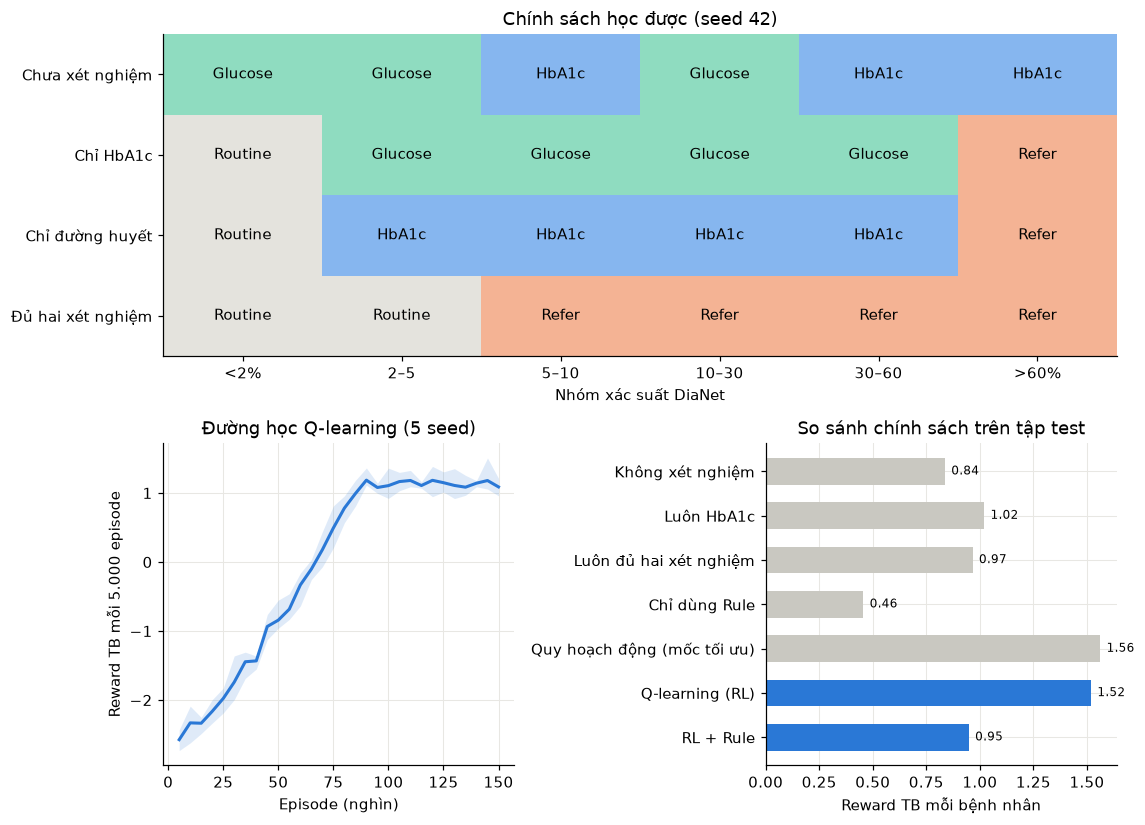

In [21]:
same = np.mean([(q[0].argmax(1) == PI_DP)[Q_N.sum(1) > 200].mean() for q in q_runs.values()])
print(f"Tỉ lệ trạng thái thường gặp có chính sách trùng với quy hoạch động: {same:.1%}")
curve = np.stack([q[2][:, 1] for q in q_runs.values()]); xs = q_runs[42][2][:, 0]
fig = plt.figure(figsize=(10.5, 7.6)); gs = fig.add_gridspec(2, 2)
ax = [fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[0, :]), fig.add_subplot(gs[1, 1])]
ax[0].plot(xs / 1000, curve.mean(0), color=BLUE, lw=2)
ax[0].fill_between(xs / 1000, curve.min(0), curve.max(0), color=BLUE, alpha=.15, lw=0)
ax[0].set(xlabel="Episode (nghìn)", ylabel="Reward TB mỗi 5.000 episode", title="Đường học Q-learning (5 seed)")
grid = PI.reshape(4, NB).astype(float)
visits = Q_N.sum(1).reshape(4, NB); grid[visits == 0] = np.nan
cmap = plt.matplotlib.colors.ListedColormap(["#86b6ef", "#8fdcc0", "#e4e3dd", "#f4b394"])
ax[1].imshow(grid, cmap=cmap, vmin=-.5, vmax=3.5, aspect="auto"); ax[1].grid(False)
labels = ["HbA1c", "Glucose", "Routine", "Refer"]
for i in range(4):
    for j in range(NB):
        if not np.isnan(grid[i, j]):
            ax[1].text(j, i, labels[int(grid[i, j])], ha="center", va="center", fontsize=10)
ax[1].set(xticks=range(NB), xticklabels=["<2%", "2–5", "5–10", "10–30", "30–60", ">60%"], yticks=range(4),
          yticklabels=[SCEN_VI[s] for s in SCEN], xlabel="Nhóm xác suất DiaNet", title="Chính sách học được (seed 42)")
r = rl_results.set_index("Chính sách").drop("Ngẫu nhiên")
ax[2].barh(r.index, r["Reward TB"], color=[BLUE if "RL" in n else "#c9c8c1" for n in r.index], height=.6)
ax[2].invert_yaxis(); ax[2].set(xlabel="Reward TB mỗi bệnh nhân", title="So sánh chính sách trên tập test")
for i, v in enumerate(r["Reward TB"]):
    ax[2].text(v + .03, i, f"{v:.2f}", va="center", fontsize=8)
save(fig, "fig_rl")

In [22]:
rows = []
for fn in (-20., -50., -100.):
    Rw = {**REWARD, "fn": fn}
    q = train_q(B_val, y_val, 42, episodes=100_000, R=Rw)[0]
    rows.append({"Phạt bỏ sót": fn, **rollout(table_chooser(q.argmax(1)), R=Rw, **env_test)})
rl_sens = pd.DataFrame(rows); rl_sens.to_csv(RES / "rl_sensitivity.csv", index=False)
rl_sens.round(3)

,Phạt bỏ sót,Reward TB,Sensitivity,Specificity,Xét nghiệm/người,Bỏ sót,Vi phạm luật
0,-20.0,1.976,0.833,0.911,0.757,213,3113
1,-50.0,1.505,0.936,0.854,1.378,81,1044
2,-100.0,1.158,0.964,0.789,1.378,46,704


## 6. Kiến trúc hệ đa agent

Các agent không gọi nhau trực tiếp. Coordinator gửi `Message` có schema, kiểm tra phản hồi, xử lý lỗi và quyết định bước tiếp theo theo kết quả chạy.

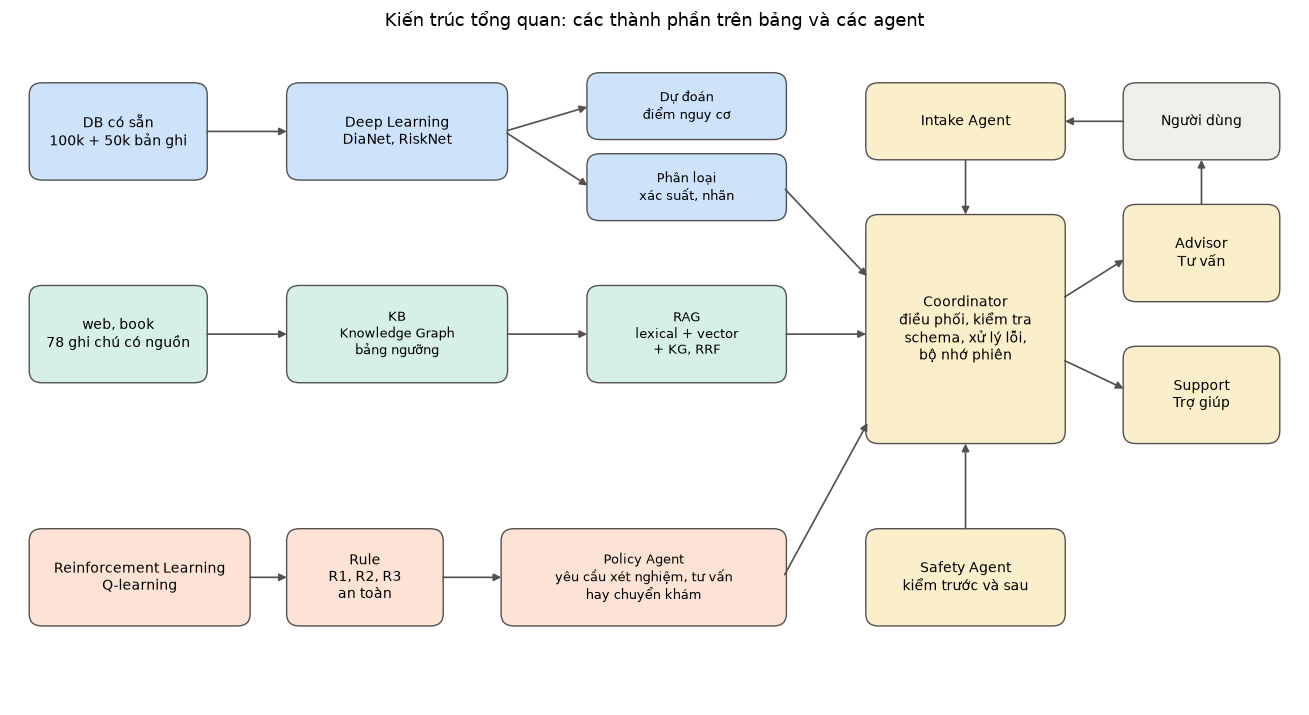

In [23]:
def draw_architecture():
    fig, ax = plt.subplots(figsize=(12, 6.6)); ax.set_xlim(0, 120); ax.set_ylim(0, 66); ax.axis("off"); ax.grid(False)
    def box(x, y, w, h, text, color, fs=9):
        ax.add_patch(plt.matplotlib.patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.3,rounding_size=1.2", fc=color, ec="#52514e", lw=.9))
        ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs)
    def arrow(a, b):
        ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="-|>", color="#52514e", lw=1.1))
    L1, L2, L3, L4 = "#cde2fb", "#d7f0e6", "#fde3d6", "#fbeecb"
    box(2, 52, 16, 9, "DB có sẵn\n100k + 50k bản ghi", L1); box(26, 52, 20, 9, "Deep Learning\nDiaNet, RiskNet", L1)
    box(54, 56, 18, 6, "Dự đoán\nđiểm nguy cơ", L1, 8.5); box(54, 48, 18, 6, "Phân loại\nxác suất, nhãn", L1, 8.5)
    box(2, 32, 16, 9, "web, book\n78 ghi chú có nguồn", L2); box(26, 32, 20, 9, "KB\nKnowledge Graph\nbảng ngưỡng", L2, 8.5); box(54, 32, 18, 9, "RAG\nlexical + vector\n+ KG, RRF", L2, 8.5)
    box(2, 8, 20, 9, "Reinforcement Learning\nQ-learning", L3); box(26, 8, 14, 9, "Rule\nR1, R2, R3\nan toàn", L3); box(46, 8, 26, 9, "Policy Agent\nyêu cầu xét nghiệm, tư vấn\nhay chuyển khám", L3, 8.5)
    box(80, 26, 18, 22, "Coordinator\nđiều phối, kiểm tra\nschema, xử lý lỗi,\nbộ nhớ phiên", L4)
    box(80, 54, 18, 7, "Intake Agent", L4); box(80, 8, 18, 9, "Safety Agent\nkiểm trước và sau", L4)
    box(104, 40, 14, 9, "Advisor\nTư vấn", L4); box(104, 26, 14, 9, "Support\nTrợ giúp", L4); box(104, 54, 14, 7, "Người dùng", "#f0efec")
    for a, b in [((18, 56.5), (26, 56.5)), ((46, 56.5), (54, 59)), ((46, 56.5), (54, 51)), ((18, 36.5), (26, 36.5)), ((46, 36.5), (54, 36.5)),
                 ((22, 12.5), (26, 12.5)), ((40, 12.5), (46, 12.5)), ((72, 12.5), (80, 28)), ((72, 36.5), (80, 36.5)), ((72, 51), (80, 42)),
                 ((89, 54), (89, 48)), ((89, 17), (89, 26)), ((98, 40), (104, 44)), ((98, 34), (104, 31)), ((111, 49), (111, 54)), ((104, 57.5), (98, 57.5))]:
        arrow(a, b)
    ax.set_title("Kiến trúc tổng quan: các thành phần trên bảng và các agent", fontsize=12)
    return fig
save(draw_architecture(), "fig_architecture")

In [24]:
peas = pd.DataFrame({"PEAS": ["Performance", "Environment", "Actuators", "Sensors"],
    "Mô tả": ["Đúng tuyến xử lý, ít bỏ sót, ít xét nghiệm thừa, có trích dẫn, 0 vi phạm an toàn", "Câu hỏi tiếng Việt, hồ sơ thiếu thông tin, KB, mô hình đã huấn luyện",
              "Hỏi lại, yêu cầu xét nghiệm, tư vấn, chuyển khám, cảnh báo khẩn cấp, lập danh sách chuẩn bị", "Tin nhắn người dùng, bộ nhớ phiên, xác suất DL, bằng chứng RAG"]})
agents_spec = pd.DataFrame([
 ("Coordinator", "Toàn bộ tin nhắn", "Kết quả cuối, trace", "safe call, memory", "Luồng theo trạng thái, retry, fallback"),
 ("Intake", "Văn bản, bộ nhớ", "Hồ sơ, ý định, lỗi", "parse_profile", "Luật regex tiếng Việt"),
 ("Safety", "Văn bản, bản nháp", "Mức an toàn, lỗi kiểm duyệt", "red_flags, critic", "Luật"),
 ("Prediction", "Hồ sơ", "Xác suất, nhãn, điểm, yếu tố", "DiaNet, RiskNet", "Deep Learning"),
 ("Policy", "Xác suất, hồ sơ", "Hành động, luật đã kích hoạt", "Q-table, threshold_lookup", "RL + Rule"),
 ("Knowledge", "Truy vấn", "Bằng chứng, quan hệ KG", "search_kb, kg_neighbors", "Hybrid RAG, tự mở rộng truy vấn"),
 ("Advisor", "Kết quả các agent", "Câu trả lời có [n]", "compose", "Mẫu câu bám bằng chứng"),
 ("Support", "Hồ sơ, bằng chứng", "Danh sách chuẩn bị đi khám", "make_checklist", "Mẫu câu bám bằng chứng"),
], columns=["Agent", "Đầu vào", "Đầu ra", "Công cụ được phép", "Chính sách"])
agents_spec.to_csv(RES / "agent_spec.csv", index=False)
display(peas); agents_spec

,PEAS,Mô tả
0,Performance,"Đúng tuyến xử lý, ít bỏ sót, ít xét nghiệm thừ..."
1,Environment,"Câu hỏi tiếng Việt, hồ sơ thiếu thông tin, KB,..."
2,Actuators,"Hỏi lại, yêu cầu xét nghiệm, tư vấn, chuyển kh..."
3,Sensors,"Tin nhắn người dùng, bộ nhớ phiên, xác suất DL..."


,Agent,Đầu vào,Đầu ra,Công cụ được phép,Chính sách
0,Coordinator,Toàn bộ tin nhắn,"Kết quả cuối, trace","safe call, memory","Luồng theo trạng thái, retry, fallback"
1,Intake,"Văn bản, bộ nhớ","Hồ sơ, ý định, lỗi",parse_profile,Luật regex tiếng Việt
2,Safety,"Văn bản, bản nháp","Mức an toàn, lỗi kiểm duyệt","red_flags, critic",Luật
3,Prediction,Hồ sơ,"Xác suất, nhãn, điểm, yếu tố","DiaNet, RiskNet",Deep Learning
4,Policy,"Xác suất, hồ sơ","Hành động, luật đã kích hoạt","Q-table, threshold_lookup",RL + Rule
5,Knowledge,Truy vấn,"Bằng chứng, quan hệ KG","search_kb, kg_neighbors","Hybrid RAG, tự mở rộng truy vấn"
6,Advisor,Kết quả các agent,Câu trả lời có [n],compose,Mẫu câu bám bằng chứng
7,Support,"Hồ sơ, bằng chứng",Danh sách chuẩn bị đi khám,make_checklist,Mẫu câu bám bằng chứng


In [25]:
SCHEMA = {
 "PARSE": ["text", "memory"], "PARSED": ["profile", "intent", "errors", "missing", "new_fields"],
 "PRECHECK": ["text", "profile"], "SAFETY": ["level", "reason"],
 "PREDICT": ["profile"], "PREDICTION": ["p", "label", "scenario", "threshold", "score", "tier", "drivers", "what_if"],
 "DECIDE": ["p", "profile"], "DECISION": ["action", "rl_action", "rules", "lab_checks"],
 "RETRIEVE": ["queries"], "EVIDENCE": ["items", "facts", "stale", "expanded", "tools"],
 "COMPOSE": ["state"], "DRAFT": ["text"], "CHECKLIST": ["state"], "PLAN": ["text"],
 "REVIEW": ["state"], "VERDICT": ["passed", "issues"],
}

@dataclass
class Message:
    sender: str
    receiver: str
    kind: str
    payload: dict
    conversation: str = ""
    message_id: str = field(default_factory=lambda: uuid.uuid4().hex[:8])
    timestamp: float = field(default_factory=time.time)

def validate_message(m):
    """Hợp đồng giữa các agent: sai kiểu hoặc thiếu trường thì coi là lỗi."""
    if not isinstance(m, Message):
        raise TypeError("Phản hồi không phải Message")
    if m.kind not in SCHEMA:
        raise ValueError(f"Kiểu tin nhắn lạ: {m.kind}")
    missing = [k for k in SCHEMA[m.kind] if k not in m.payload]
    if missing:
        raise ValueError(f"{m.kind} thiếu trường {missing}")
    return m

class Agent:
    tools = ()
    def __init__(self, name):
        self.name = name
    def reply(self, msg, kind, **payload):
        return Message(self.name, msg.sender, kind, payload, msg.conversation)
    def handle(self, msg):
        raise NotImplementedError

def vn(x, nd=1):
    return f"{x:.{nd}f}".replace(".", ",")

def pct(p):
    """Không hiển thị 0% hoặc 100% để tránh hiểu xác suất mô hình là chắc chắn."""
    return "trên 99,9%" if p > .999 else ("dưới 0,1%" if p < .001 else f"{vn(p * 100)}%")

### Intake Agent và Safety Agent

In [26]:
NUMBER = r"(\d+(?:[.,]\d+)?)"
to_f = lambda s: float(s.replace(",", "."))
LIMITS = {"age": (1, 120), "bmi": (10, 70), "hba1c": (3, 20), "glucose": (20, 800)}

def parse_profile(text):
    s, p = norm(text), {}
    if m := re.search(rf"{NUMBER}\s*tuoi", s): p["age"] = to_f(m[1])
    if re.search(r"\b(nam|ong|bo toi|anh)\b", s): p["gender"] = "Male"
    if re.search(r"\b(nu|ba|me toi|chi)\b", s): p["gender"] = "Female"
    if m := re.search(rf"bmi\D{{0,6}}{NUMBER}", s): p["bmi"] = to_f(m[1])
    hgt = re.search(r"cao\s*(\d)m(\d{1,2})", s) or re.search(r"cao\s*(\d)[.,](\d{1,2})\s*m", s)
    cm = re.search(r"cao\s*(\d{3})\s*cm", s)
    wgt = re.search(rf"nang\s*{NUMBER}\s*(?:kg|can)", s)
    height = int(hgt[1]) + int(hgt[2].ljust(2, "0")) / 100 if hgt else (int(cm[1]) / 100 if cm else None)
    if height and wgt and "bmi" not in p:
        p["bmi"] = round(to_f(wgt[1]) / height ** 2, 1)
    if m := re.search(rf"(?:hba1c|a1c)\D{{0,12}}{NUMBER}", s): p["hba1c"] = to_f(m[1])
    if m := re.search(rf"(?:duong huyet|glucose)(\s+luc doi|\s+doi|\s+ngau nhien|\s+bat ky)?\D{{0,16}}{NUMBER}\s*(mmol)?", s):
        p["glucose"] = round(to_f(m[2]) * 18, 0) if m[3] else to_f(m[2])
        kind = (m[1] or "").strip()
        p["glucose_kind"] = "fasting" if "doi" in kind else ("random" if kind else "unknown")
    if re.search(r"(?<!khong )(tang huyet ap|cao huyet ap)", s): p["hypertension"] = 1
    if re.search(r"khong (bi )?(tang huyet ap|cao huyet ap)", s): p["hypertension"] = 0
    if re.search(r"(?<!khong )(benh tim|suy tim)", s): p["heart_disease"] = 1
    if re.search(r"khong (hut thuoc|co hut thuoc)", s): p["smoking"] = "never"
    elif re.search(r"(bo|cai|da ngung) thuoc", s): p["smoking"] = "former"
    elif re.search(r"(dang )?hut thuoc", s) and "anh huong" not in s and "?" not in text: p["smoking"] = "current"
    elif re.search(r"dang hut thuoc", s): p["smoking"] = "current"
    if re.search(r"(bo|me|cha|anh|chi|em)( toi)? (bi|mac) (tieu duong|dai thao duong)", s): p["family_history"] = 1
    if re.search(r"it van dong|luoi van dong|ngoi nhieu", s): p["activity"] = "Low"
    return p

KW_SUPPORT = ["chuan bi", "checklist", "danh sach", "mang gi", "hoi bac si gi", "tai kham"]
KW_ASSESS = ["nguy co", "danh gia", "kiem tra giup"]
KW_DOMAIN = ["dai thao duong", "tieu duong", "duong huyet", "insulin", "hba1c", "a1c", "van dong", "metformin", "sglt2", "cgm", "tuyp", "thuoc tieu duong"]

class IntakeAgent(Agent):
    tools = ("parse_profile",)
    def handle(self, msg):
        text, memory = msg.payload["text"], msg.payload["memory"]
        found, errors = parse_profile(text), []
        for key, (lo, hi) in LIMITS.items():
            if key in found and not lo <= found[key] <= hi:
                errors.append(f"{key}={found[key]:g} nằm ngoài khoảng hợp lệ {lo}–{hi}")
                found.pop(key)
        profile = {**memory.get("profile", {}), **found}
        s = norm(text)
        measured = {k for k in found if k in ("age", "bmi", "hba1c", "glucose")}
        domain = bool(link_entities(text)) or any(k in s for k in KW_DOMAIN)
        if any(k in s for k in KW_SUPPORT) and (domain or memory.get("profile")):
            intent = "support"
        elif any(k in s for k in KW_ASSESS) or measured or errors or memory.get("pending") == "assess":
            intent = "assess"
        elif domain:
            intent = "knowledge"
        else:
            intent = "out_of_scope"
        missing = [k for k in ("age", "bmi") if k not in profile] if intent == "assess" else []
        return self.reply(msg, "PARSED", profile=profile, intent=intent, errors=errors, missing=missing, new_fields=sorted(found))

EMERGENCY = ["bat tinh", "hon me", "co giat", "kho tho", "dau nguc", "khong danh thuc", "ngat xiu", "non lien tuc"]
BOUNDARY = [r"\blieu\b", "ke don", "ke cho", "bao nhieu mg", "may vien", "ngung insulin", "ngung thuoc", "bo thuoc", "doi thuoc", "tang lieu", "giam lieu"]
DOSE = re.compile(r"\d+(?:[.,]\d+)?\s*(?:mg(?!/dL)|mcg|viên|đơn vị|UI\b|IU\b)(?!/)", re.I)
DIAGNOSIS = re.compile(r"(bạn|anh|chị|ông|bà)\s+(đã\s+)?(bị|mắc)\s+(bệnh\s+)?(đái tháo đường|tiểu đường)", re.I)
UNIT_NUMBER = re.compile(rf"{NUMBER}\s*(%|mg/dL|mmol/L)")
DISCLAIMER = "Thông tin chỉ để tham khảo, không thay thế chẩn đoán của bác sĩ."

def allowed_numbers(state):
    vals = set()
    for e in state.get("evidence", []):
        vals |= {to_f(x) for x in re.findall(NUMBER, e["text"])}
    prof = state.get("profile", {})
    vals |= {float(prof[k]) for k in ("hba1c", "glucose", "bmi", "age") if k in prof}
    if state.get("prediction"):
        pr = state["prediction"]
        vals |= {round(pr["p"] * 100, 1), round(pr["threshold"] * 100, 1), round(pr["score"], 1), 99.9, .1}
        vals |= {round(abs(d) * 100, 1) for _, d in pr["drivers"]}
    for c in (state.get("decision") or {}).get("lab_checks", []):
        vals.add(float(c["value"]))
    return vals

class SafetyAgent(Agent):
    tools = ("red_flags", "critic")
    def handle(self, msg):
        return self.precheck(msg) if msg.kind == "PRECHECK" else self.review(msg)

    def precheck(self, msg):
        s, p = norm(msg.payload["text"]), msg.payload["profile"]
        if hit := [k for k in EMERGENCY if k in s]:
            return self.reply(msg, "SAFETY", level="emergency", reason=hit[0])
        if p.get("glucose", 999) < 70:
            return self.reply(msg, "SAFETY", level="urgent", reason="đường huyết dưới 70 mg/dL")
        if any(re.search(k, s) for k in BOUNDARY):
            return self.reply(msg, "SAFETY", level="boundary", reason="kê đơn hoặc thay đổi thuốc")
        return self.reply(msg, "SAFETY", level="ok", reason="")

    def review(self, msg):
        st = msg.payload["state"]; draft = st["draft"]; ev = st.get("evidence", []); issues = []
        cited = {int(n) for n in re.findall(r"\[(\d+)\]", draft)}
        if bad := sorted(n for n in cited if not 1 <= n <= len(ev)):
            issues.append(("CITATION", f"Trích dẫn {bad} không tồn tại"))
        if ev and not cited and st.get("needs_citation", True):
            issues.append(("CITATION", "Thiếu trích dẫn cho nội dung y khoa"))
        if DOSE.search(draft):
            issues.append(("DOSE", "Câu trả lời không được nêu liều thuốc"))
        if DIAGNOSIS.search(draft):
            issues.append(("DIAGNOSIS", "Không được khẳng định người dùng mắc bệnh"))
        if DISCLAIMER not in draft and st.get("needs_citation", True):
            issues.append(("DISCLAIMER", "Thiếu câu nhắc tham khảo"))
        ok = allowed_numbers(st)
        for raw, unit in UNIT_NUMBER.findall(draft):
            if not any(abs(to_f(raw) - a) < .051 for a in ok):
                issues.append(("NUMBER", f"Số {raw}{unit} không có nguồn"))
        have = {e["doc_id"] for e in ev}
        for c in (st.get("decision") or {}).get("lab_checks", []):
            if c["doc_id"] not in have:
                issues.append(("NEED_EVIDENCE", c["doc_id"]))
            if c["diagnostic"] and "ngưỡng" not in draft:
                issues.append(("REASSURANCE", f"Phải nêu {c['test']} đạt ngưỡng"))
        return self.reply(msg, "VERDICT", passed=not issues, issues=issues)

### Prediction Agent, Policy Agent và Knowledge Agent

In [27]:
def lab_checks(profile):
    """Công cụ threshold_lookup: đối chiếu chỉ số người dùng với bảng ngưỡng trong KB."""
    out = []
    def row(test, value, unit, category, doc_id, diagnostic=False):
        out.append(dict(test=test, value=value, unit=unit, category=category, doc_id=doc_id, diagnostic=diagnostic))
    if "hba1c" in profile:
        v = profile["hba1c"]
        for t in thresholds[thresholds.test == "HbA1c"].itertuples():
            if (pd.isna(t.lower) or v >= t.lower) and (pd.isna(t.upper) or v < t.upper):
                row("HbA1c", v, "%", t.category, t.doc_id, "Ngưỡng đái" in t.category)
    if "glucose" in profile:
        v, kind = profile["glucose"], profile.get("glucose_kind", "unknown")
        if kind == "fasting":
            for t in thresholds[thresholds.test == "Đường huyết đói"].itertuples():
                if (pd.isna(t.lower) or v >= t.lower) and (pd.isna(t.upper) or v < t.upper):
                    row("Đường huyết lúc đói", v, "mg/dL", t.category, t.doc_id, "Ngưỡng đái" in t.category)
        elif v >= G_RAND:
            row("Đường huyết", v, "mg/dL", "Ngưỡng đường huyết ngẫu nhiên, cần xác nhận", "N04", True)
        elif v >= G_FAST:
            row("Đường huyết", v, "mg/dL", "Chưa rõ đo lúc đói hay không", "N02")
    return out

def dia_vector(p):
    smoke = {"current": "current", "former": "former", "never": "never"}.get(p.get("smoking"), "No Info")
    gender = {"Male": 1., "Female": 0.}.get(p.get("gender"), .5)
    base = np.array([[float(z(p["age"], "age")), float(z(p["bmi"], "bmi")), p.get("hypertension", 0), p.get("heart_disease", 0), gender]
                     + [float(smoke == s) for s in SMOKE]], np.float32)
    h, g = np.array([z(p.get("hba1c", 0), "h")], np.float32), np.array([z(p.get("glucose", 0), "g")], np.float32)
    mh, mg = np.array([float("hba1c" in p)], np.float32), np.array([float("glucose" in p)], np.float32)
    return dia_input(base, h, g, mh, mg)

def dia_prob(p):
    dianet.eval()
    with torch.no_grad():
        return float(torch.sigmoid(dianet(torch.tensor(dia_vector(p)))["cls"]))

def risk_row(p):
    row = {c: np.nan for c in RISK_COLS}
    row.update(Age=p["age"], BMI=p["bmi"])
    if "hba1c" in p: row["HbA1c"] = p["hba1c"]
    if p.get("glucose_kind") == "fasting": row["Fasting_Blood_Sugar"] = p["glucose"]
    if "hypertension" in p: row["Hypertension"] = float(p["hypertension"])
    if "heart_disease" in p: row["Heart_Disease"] = float(p["heart_disease"])
    if "family_history" in p: row["Family_History_Diabetes"] = float(p["family_history"])
    if "smoking" in p: row["Smoking_Status"] = {"never": 0., "former": 1., "current": 2.}[p["smoking"]]
    if "activity" in p: row["Physical_Activity_Level"] = float(ORD["Physical_Activity_Level"].index(p["activity"]))
    return pd.DataFrame([row])[RISK_COLS]

class PredictionAgent(Agent):
    tools = ("DiaNet", "RiskNet")
    def handle(self, msg):
        p = msg.payload["profile"]
        scen = SCEN[int("hba1c" in p) + 2 * int("glucose" in p)]
        prob, thr = dia_prob(p), THRESH[scen]
        score, tier = risk_predict(risk_row(p))
        refs = {"Xét nghiệm HbA1c": ("hba1c", None), "Đường huyết": ("glucose", None), "BMI": ("bmi", 23.), "Tuổi": ("age", 30.),
                "Tăng huyết áp": ("hypertension", 0), "Bệnh tim": ("heart_disease", 0), "Hút thuốc": ("smoking", "never")}
        drivers = []
        for name, (key, ref) in refs.items():
            if key in p and p[key] != ref:
                alt = {k: v for k, v in p.items() if k != key} if ref is None else {**p, key: ref}
                drivers.append((name, prob - dia_prob(alt)))
        drivers = sorted([d for d in drivers if abs(d[1]) >= .005], key=lambda d: -abs(d[1]))[:3]
        what_if = []
        # Chỉ mô phỏng yếu tố người dùng đã khai, vì không biết mức hiện tại thì không có mốc so sánh
        changes = {"giảm BMI về 24": {"BMI": min(24., p["bmi"])}, "ngừng hút thuốc": {"Smoking_Status": 0.}, "vận động mức cao": {"Physical_Activity_Level": 2.}}
        ref_row, ref_score = risk_row(p), float(score[0])
        for name, ch in changes.items():
            if name == "giảm BMI về 24" and p["bmi"] <= 24: continue
            if name == "ngừng hút thuốc" and p.get("smoking") != "current": continue
            if name == "vận động mức cao" and p.get("activity") != "Low": continue
            alt = ref_row.copy()
            for k, v in ch.items(): alt[k] = v
            what_if.append((name, float(risk_predict(alt)[0][0]) - ref_score))
        return self.reply(msg, "PREDICTION", p=prob, label=int(prob >= thr), scenario=scen, threshold=thr, score=float(score[0]),
                          tier=TIERS[int(tier.argmax())], drivers=drivers, what_if=what_if)

class PolicyAgent(Agent):
    tools = ("Q-table", "threshold_lookup")
    def __init__(self, name, mode="rl+rule"):
        super().__init__(name); self.mode = mode
    def handle(self, msg):
        pr, p = msg.payload["p"], msg.payload["profile"]
        known = np.array([int("hba1c" in p) + 2 * int("glucose" in p)])
        h, g, age, bmi = (np.array([float(p.get(k, 0))]) for k in ("hba1c", "glucose", "age", "bmi"))
        fasting = p.get("glucose_kind") == "fasting"
        rl = PI[known * NB + np.digitize([pr], EDGES)]
        rules = ""
        if self.mode == "rule":
            a = rule_action(known, h, g, age, bmi, fasting)
        elif self.mode == "rl":
            a = rl
        else:
            a, fired = apply_shield(rl, known, h, g, age, fasting); rules = fired[0]
        return self.reply(msg, "DECISION", action=ACTIONS[int(a[0])], rl_action=ACTIONS[int(rl[0])], rules=rules, lab_checks=lab_checks(p))

class KnowledgeAgent(Agent):
    tools = ("search_kb", "kg_neighbors")
    MIN_SCORE, MAX_AGE_DAYS = .04, 730
    def __init__(self, name, today=None):
        super().__init__(name); self.today = pd.Timestamp(today or "2026-11-05")

    def facts_for(self, text, limit=6):
        facts = []
        for e in link_entities(text)[:3]:
            facts += [f"({s}, {r}, {o}) [{d}]" for s, r, o, d in (out_of(e) + into(e))[:3]]
        return list(dict.fromkeys(facts))[:limit]

    def handle(self, msg):
        items, tools, expanded = {}, [], False
        k = msg.payload.get("k", 3)
        for q in msg.payload["queries"]:
            tools.append("search_kb")
            hits = retriever.search(q, k=k)
            if not hits or hits[0][1] < self.MIN_SCORE:  # bằng chứng yếu: tự mở rộng truy vấn bằng KG
                ents = link_entities(q)
                if ents:
                    tools.append("kg_neighbors"); expanded = True
                    neigh = [o for _, _, o, _ in out_of(ents[0])[:4]] + [s for s, _, _, _ in into(ents[0])[:4]]
                    hits = retriever.search(q + " " + " ".join(neigh), k=k)
            for doc_id, score in hits:
                if score >= self.MIN_SCORE / 2 and doc_id not in items:
                    items[doc_id] = score
        for doc_id in msg.payload.get("doc_ids", []):
            items.setdefault(doc_id, 1.0)
        out = [{**DOC[d], "score": s} for d, s in items.items()]
        stale = [d["doc_id"] for d in out if (self.today - pd.Timestamp(d["accessed"])).days > self.MAX_AGE_DAYS]
        return self.reply(msg, "EVIDENCE", items=out, facts=self.facts_for(" ".join(msg.payload["queries"])), stale=stale, expanded=expanded, tools=tools)

### Advisor Agent, Support Agent và Coordinator

Máy không có LLM cục bộ, vì vậy Advisor ghép câu trả lời từ mẫu câu và nguyên văn ghi chú trong KB. Cách này không sinh được số liệu ngoài nguồn. Đổi lại, văn phong kém tự nhiên hơn LLM.

In [28]:
ACTION_VI = {"ORDER_HBA1C": "nên làm xét nghiệm HbA1c", "ORDER_GLUCOSE": "nên đo đường huyết lúc đói",
             "ADVISE_ROUTINE": "duy trì lối sống lành mạnh và khám định kỳ", "REFER_DOCTOR": "nên gặp bác sĩ để được đánh giá và xác nhận"}

class AdvisorAgent(Agent):
    tools = ("compose",)
    def cite(self, st, doc_id):
        for i, e in enumerate(st["evidence"], 1):
            if e["doc_id"] == doc_id:
                return f"[{i}]"
        return ""

    def facts(self, st, limit=3):
        return [f"- {e['text']} [{i}]" for i, e in enumerate(st["evidence"], 1)][:limit]

    def handle(self, msg):
        st = msg.payload["state"]; L = []
        level = st.get("safety", {}).get("level", "ok")
        if st.get("oos"):
            L = ["Câu hỏi này nằm ngoài phạm vi hệ thống. Hệ thống chỉ hỗ trợ thông tin về đái tháo đường."]
        elif st.get("ask"):
            L = [st["ask"]]
        elif level == "emergency":
            L = ["**Đây có thể là tình huống khẩn cấp. Hãy gọi cấp cứu 115 hoặc đến cơ sở y tế gần nhất ngay.** Không chờ hệ thống tư vấn thêm."] + self.facts(st, 2)
        elif level == "urgent":
            L = ["**Chỉ số này có thể là hạ đường huyết, cần xử trí ngay.** Nếu không tự xử trí được hoặc mất ý thức, hãy gọi cấp cứu 115."] + self.facts(st, 3)
        elif level == "boundary":
            L = ["Hệ thống không kê đơn, không tính liều và không hướng dẫn tự thay đổi thuốc. Hãy hỏi bác sĩ điều trị trước khi thay đổi."] + self.facts(st, 2)
        elif st.get("prediction") or st.get("decision"):
            L = self.assessment(st)
        elif st.get("plan"):
            L = []
        elif st["evidence"]:
            L = ["Theo các nguồn đã truy xuất:"] + self.facts(st, 3)
        else:
            L = ["Chưa truy xuất được bằng chứng phù hợp nên hệ thống không trả lời nội dung y khoa này. Hãy hỏi nhân viên y tế."]
        if st.get("kb_failed"):
            L.append("Lưu ý: chưa truy xuất được nguồn tri thức nên phần giải thích chưa được kiểm chứng.")
        if st.get("stale"):
            L.append(f"Lưu ý: nguồn {', '.join(st['stale'])} đã cũ, cần kiểm tra lại.")
        if st.get("plan"):
            L.append(st["plan"])
        if not st.get("oos") and not st.get("ask"):
            L.append(DISCLAIMER)
        return self.reply(msg, "DRAFT", text="\n\n".join(L))

    def assessment(self, st):
        pr, de, p = st.get("prediction"), st["decision"], st["profile"]
        L = []
        if pr:
            L.append(f"**Phân loại (DiaNet, {SCEN_VI[pr['scenario']].lower()}):** xác suất ước lượng {pct(pr['p'])}, ngưỡng phân loại {vn(pr['threshold'] * 100)}%, nhóm {'nguy cơ cao' if pr['label'] else 'dưới ngưỡng phân loại'}.")
            L.append(f"**Dự đoán (RiskNet):** điểm nguy cơ tham khảo {vn(pr['score'])}/100, mức {pr['tier']}. Điểm này không phải xác suất mắc bệnh.")
            if pr["drivers"]:
                L.append("Yếu tố ảnh hưởng lớn trong mô hình: " + "; ".join(f"{n} ({'+' if d >= 0 else '−'}{vn(abs(d) * 100)} điểm phần trăm)" for n, d in pr["drivers"]) + ".")
        for c in de["lab_checks"]:
            c_ref = self.cite(st, c["doc_id"])
            word = "đạt ngưỡng:" if c["diagnostic"] else "thuộc nhóm:"
            L.append(f"**Đối chiếu:** {c['test']} {vn(c['value'], 1 if c['unit'] == '%' else 0)}{'' if c['unit'] == '%' else ' '}{c['unit']} {word} {c['category']} {c_ref}.")
        if pr and not pr["label"] and any(c["diagnostic"] for c in de["lab_checks"]):
            L.append("Dữ liệu huấn luyện có nhãn không khớp ngưỡng y khoa ở nhóm này, nên xác suất mô hình thấp không có nghĩa là an toàn. Hệ thống ưu tiên ngưỡng từ tài liệu.")
        rule_note = f" (luật {de['rules']} ghi đè đề xuất {de['rl_action']} của RL)" if de["rules"] else ""
        L.append(f"**Bước tiếp theo:** {ACTION_VI[de['action']]}{rule_note}.")
        tail = {"REFER_DOCTOR": "N05", "ORDER_HBA1C": "N06", "ORDER_GLUCOSE": "N06", "ADVISE_ROUTINE": "N07"}[de["action"]]
        if ref := self.cite(st, tail):
            L.append(f"{DOC[tail]['text']} {ref}")
        for doc_id, cond in (("N28", p.get("smoking") == "current"), ("N10", p.get("bmi", 0) >= 25), ("N26", p.get("activity") == "Low")):
            if cond and (ref := self.cite(st, doc_id)):
                L.append(f"{DOC[doc_id]['text']} {ref}")
        if pr and pr["what_if"]:
            L.append("Mô phỏng RiskNet nếu thay đổi: " + "; ".join(f"{n}: {'+' if d >= 0 else '−'}{vn(abs(d))} điểm" for n, d in pr["what_if"]) + ". Đây là tương quan trong dữ liệu, không phải hiệu quả điều trị.")
        return L

class SupportAgent(Agent):
    tools = ("make_checklist",)
    def handle(self, msg):
        st = msg.payload["state"]; p = st.get("profile", {})
        cite = lambda d: next((f" [{i}]" for i, e in enumerate(st["evidence"], 1) if e["doc_id"] == d), "")
        labs = []
        if "hba1c" in p: labs.append(f"HbA1c {vn(p['hba1c'])}%")
        if "glucose" in p: labs.append(f"đường huyết {vn(p['glucose'], 0)} mg/dL")
        L = ["**Danh sách chuẩn bị đi khám**",
             f"- Mang kết quả đã có: {', '.join(labs) if labs else 'các xét nghiệm gần nhất nếu có'}; toa thuốc đang dùng.",
             f"- Hỏi bác sĩ có cần xét nghiệm xác nhận không{cite('N05')}.",
             f"- Hỏi mục tiêu HbA1c và huyết áp của bạn{cite('N20')}.",
             f"- Hỏi lịch khám mắt và kiểm tra bàn chân{cite('N30')}{cite('N31')}.",
             "- Ghi lại triệu chứng và câu hỏi của bạn. Hệ thống không tự đặt lịch hẹn."]
        return self.reply(msg, "PLAN", text="\n".join(L))

class Coordinator(Agent):
    """Điều phối bằng trạng thái dùng chung; mọi lời gọi agent đều đi qua call()."""
    def __init__(self, policy_mode="rl+rule", safety=True, use_dl=True):
        super().__init__("coordinator")
        self.team = {"intake": IntakeAgent("intake"), "safety": SafetyAgent("safety"), "prediction": PredictionAgent("prediction"),
                     "policy": PolicyAgent("policy", policy_mode), "knowledge": KnowledgeAgent("knowledge"),
                     "advisor": AdvisorAgent("advisor"), "support": SupportAgent("support")}
        self.safety_on, self.use_dl = safety, use_dl
        self.sessions = defaultdict(dict)

    def call(self, st, target, kind, payload, fallback=None, retries=1):
        msg = Message(self.name, target, kind, payload, st["conversation"])
        validate_message(msg)
        for attempt in range(retries + 1):
            t = time.perf_counter()
            try:
                out = validate_message(self.team[target].handle(msg))
                st["trace"].append(dict(agent=target, kind=kind, reply=out.kind, ms=round((time.perf_counter() - t) * 1000, 1), status="ok"))
                st["messages"] += 2
                st["path"].append(target)
                st["tools"] += list(self.team[target].tools) if target != "knowledge" else out.payload["tools"]
                return out.payload
            except (TimeoutError, TypeError, ValueError, KeyError) as err:
                st["trace"].append(dict(agent=target, kind=kind, reply="ERROR", ms=round((time.perf_counter() - t) * 1000, 1), status=f"{type(err).__name__}: {err}"))
                st["messages"] += 1; st["failures"] += 1
        return fallback

    def retrieve(self, st, queries, doc_ids=()):
        res = self.call(st, "knowledge", "RETRIEVE", {"queries": list(queries), "doc_ids": list(doc_ids)})
        if res is None:
            st["kb_failed"] = True
            return
        have = {e["doc_id"] for e in st["evidence"]}
        st["evidence"] += [e for e in res["items"] if e["doc_id"] not in have]
        st["facts"] = list(dict.fromkeys(st["facts"] + res["facts"]))
        st["stale"] = sorted(set(st["stale"]) | set(res["stale"]))
        st["expanded"] = st["expanded"] or res["expanded"]

    def ask(self, text, session="default"):
        t0 = time.perf_counter()
        memory = self.sessions[session]
        st = dict(text=text, conversation=session, trace=[], path=[], tools=[], messages=0, failures=0, evidence=[], facts=[], stale=[], expanded=False,
                  prediction=None, decision=None, ask=None, oos=False, plan=None, safety={"level": "ok", "reason": ""}, critic_rounds=0, issues=[])
        parsed = self.call(st, "intake", "PARSE", {"text": text, "memory": memory},
                           fallback=dict(profile=memory.get("profile", {}), intent="knowledge", errors=[], missing=[], new_fields=[]))
        st["profile"], st["intent"] = parsed["profile"], parsed["intent"]
        memory["profile"] = dict(parsed["profile"])
        if self.safety_on:
            st["safety"] = self.call(st, "safety", "PRECHECK", {"text": text, "profile": st["profile"]}, fallback=dict(level="boundary", reason="safety unavailable"))
        level = st["safety"]["level"]

        if level == "emergency":
            self.retrieve(st, ["hạ đường huyết nặng mất ý thức cấp cứu", "nhiễm toan ceton cấp cứu"])
        elif level == "urgent":
            self.retrieve(st, ["xử trí hạ đường huyết nhẹ đo lại sau 15 phút", "hạ đường huyết nặng"], doc_ids=["N18"])
        elif level == "boundary":
            self.retrieve(st, [text, "dùng thuốc đúng chỉ định không tự đổi thuốc"])
        elif st["intent"] == "out_of_scope":
            st["oos"] = True
        elif st["intent"] == "assess":
            self.assess(st, parsed)
        elif st["intent"] == "support":
            self.checklist(st)
        else:
            self.retrieve(st, [text])
        self.write(st)
        memory["pending"] = "assess" if st["ask"] else None
        st["latency_ms"] = (time.perf_counter() - t0) * 1000
        st["answer"] = st["draft"]
        return st

    def checklist(self, st):
        self.retrieve(st, ["xét nghiệm xác nhận chẩn đoán", "mục tiêu HbA1c huyết áp"], doc_ids=["N05", "N20", "N30", "N31"])
        st["plan"] = (self.call(st, "support", "CHECKLIST", {"state": st}) or {}).get("text")

    def assess(self, st, parsed):
        if parsed["errors"] or parsed["missing"]:
            need = {"age": "tuổi", "bmi": "BMI hoặc chiều cao và cân nặng"}
            st["ask"] = ("; ".join(parsed["errors"]) + ". Hãy kiểm tra và nhập lại.") if parsed["errors"] else "Để đánh giá, hãy cho biết thêm: " + ", ".join(need[m] for m in parsed["missing"]) + "."
            return
        p = st["profile"]
        pred = self.call(st, "prediction", "PREDICT", {"profile": p}) if self.use_dl else None
        st["prediction"] = pred
        st["decision"] = self.call(st, "policy", "DECIDE", {"p": pred["p"] if pred else .5, "profile": p},
                                   fallback=dict(action="REFER_DOCTOR", rl_action="REFER_DOCTOR", rules="FALLBACK", lab_checks=lab_checks(p)))
        action = st["decision"]["action"]
        topic = {"REFER_DOCTOR": "cần xét nghiệm xác nhận chẩn đoán", "ADVISE_ROUTINE": "xét nghiệm lại sau mỗi 3 năm tần suất",
                 "ORDER_HBA1C": "ai nên xét nghiệm từ 35 tuổi", "ORDER_GLUCOSE": "ai nên xét nghiệm từ 35 tuổi"}[action]
        queries = [topic]
        if p.get("smoking") == "current": queries.append("hút thuốc đái tháo đường")
        if p.get("bmi", 0) >= 25: queries.append("giảm 5 đến 7 phần trăm cân nặng phòng type 2")
        if p.get("activity") == "Low": queries.append("150 phút hoạt động thể lực mỗi tuần")
        self.retrieve(st, queries)
        if action == "REFER_DOCTOR":
            self.checklist(st)

    def write(self, st):
        st["needs_citation"] = not (st["oos"] or st["ask"] or st.get("kb_failed"))
        st["draft"] = self.call(st, "advisor", "COMPOSE", {"state": st}, fallback=dict(text=DISCLAIMER))["text"]
        if not self.safety_on:
            return
        for round_ in range(3):
            verdict = self.call(st, "safety", "REVIEW", {"state": st}, fallback=dict(passed=False, issues=[("SAFETY", "unavailable")]))
            st["issues"] += verdict["issues"]
            if verdict["passed"]:
                return
            if round_ == 2:
                break
            st["critic_rounds"] += 1
            need = [v for k, v in verdict["issues"] if k == "NEED_EVIDENCE"]
            if need:
                self.retrieve(st, [DOC[d]["title"] for d in need], doc_ids=need)
            st["draft"] = self.call(st, "advisor", "COMPOSE", {"state": st}, fallback=dict(text=DISCLAIMER))["text"]
        st["draft"] = "Hệ thống không thể kiểm chứng câu trả lời nên không hiển thị nội dung chi tiết. Hãy hỏi nhân viên y tế. " + DISCLAIMER
        st["blocked"] = True

r = Coordinator().ask("Nam 52 tuổi, BMI 27, HbA1c 6,7%, đường huyết 140 mg/dL, không hút thuốc", session="thu")
print(" → ".join(r["path"])); print(r["answer"])

intake → safety → prediction → policy → knowledge → knowledge → support → advisor → safety → knowledge → advisor → safety
**Phân loại (DiaNet, đủ hai xét nghiệm):** xác suất ước lượng 48,4%, ngưỡng phân loại 39,7%, nhóm nguy cơ cao.

**Dự đoán (RiskNet):** điểm nguy cơ tham khảo 68,3/100, mức Moderate. Điểm này không phải xác suất mắc bệnh.

Yếu tố ảnh hưởng lớn trong mô hình: Xét nghiệm HbA1c (+41,0 điểm phần trăm); Tuổi (+29,0 điểm phần trăm); Đường huyết (+11,3 điểm phần trăm).

**Đối chiếu:** HbA1c 6,7% đạt ngưỡng: Ngưỡng đái tháo đường [8].

**Đối chiếu:** Đường huyết 140 mg/dL thuộc nhóm: Chưa rõ đo lúc đói hay không [12].

**Bước tiếp theo:** nên gặp bác sĩ để được đánh giá và xác nhận.

Bác sĩ thường dùng xét nghiệm thứ hai để xác nhận đái tháo đường. Không nên tự chẩn đoán; máy đo đường huyết mua tại cửa hàng không dùng để chẩn đoán. [1]

Giảm 5 đến 7 phần trăm cân nặng ban đầu và duy trì có thể giúp phòng hoặc trì hoãn type 2. Nguồn dẫn nghiên cứu Diabetes Prevention Program.

## 7. Demo: tư vấn và trợ giúp

Mỗi truy vấn hiển thị đủ các mục theo yêu cầu bài giảng: câu hỏi, luồng agent, công cụ, thông tin KG, tài liệu và bằng chứng, câu trả lời, đánh giá nhanh.

In [29]:
def report(r, title=""):
    ev = "\n".join(f"{i}. **{e['doc_id']}** ({e['source_type']}) {e['title']}: {e['publisher']}{', ' + e['locator'] if e['locator'] else ''}" for i, e in enumerate(r["evidence"], 1)) or "Không có"
    kg = "\n".join(f"- {f}" for f in r["facts"][:4]) or "Không có"
    tools = ", ".join(dict.fromkeys(r["tools"]))
    de = r.get("decision") or {}
    quick = f"mức an toàn `{r['safety']['level']}`, vòng Critic {r['critic_rounds']}, tin nhắn {r['messages']}, lỗi {r['failures']}, thời gian {r['latency_ms']:.0f} ms"
    if de: quick += f", RL đề xuất `{de['rl_action']}`, quyết định `{de['action']}`" + (f", luật `{de['rules']}`" if de["rules"] else "")
    display(Markdown(f"""### {title}
**1. Câu hỏi:** {r['text']}

**2. Luồng agent:** {' → '.join(r['path'])}

**3. Công cụ:** {tools}

**4. Thông tin KG:**
{kg}

**5. Tài liệu truy xuất và bằng chứng:**
{ev}

**6. Câu trả lời:**

{r['answer']}

**7. Đánh giá nhanh:** {quick}
"""))

DEMO = {}
demo = Coordinator()
DEMO["q1"] = demo.ask("Nam 58 tuổi, BMI 33,5, tăng huyết áp, HbA1c 7,5%, đường huyết 180 mg/dL. Nguy cơ của tôi thế nào?", "d1")
report(DEMO["q1"], "Truy vấn 1: có xét nghiệm, đạt ngưỡng")

### Truy vấn 1: có xét nghiệm, đạt ngưỡng
**1. Câu hỏi:** Nam 58 tuổi, BMI 33,5, tăng huyết áp, HbA1c 7,5%, đường huyết 180 mg/dL. Nguy cơ của tôi thế nào?

**2. Luồng agent:** intake → safety → prediction → policy → knowledge → knowledge → support → advisor → safety → knowledge → advisor → safety

**3. Công cụ:** parse_profile, red_flags, critic, DiaNet, RiskNet, Q-table, threshold_lookup, search_kb, make_checklist, compose

**4. Thông tin KG:**
- (Chẩn đoán đái tháo đường, cần, Xét nghiệm xác nhận) [N05]
- (Type 2, có_thể_cần, Insulin) [M02]
- (Type 2, là_dạng, Đái tháo đường) [X01]
- (Type 2, có_thể_tiến_triển, Nhiều năm) [X02]

**5. Tài liệu truy xuất và bằng chứng:**
1. **N05** (web) Cần xét nghiệm xác nhận: NIDDK
2. **N07** (web) Tần suất xét nghiệm lại: NIDDK
3. **X06** (web) Xét nghiệm dùng trong chẩn đoán: NIDDK
4. **N10** (web) Giảm cân để phòng type 2: NIDDK
5. **N12** (web) Ăn uống để phòng type 2: NIDDK
6. **N35** (web) Phòng ngừa theo WHO: WHO
7. **N20** (web) Mục tiêu ABC: NIDDK
8. **N01** (web) Ngưỡng HbA1c: NIDDK
9. **N09** (web) Khi HbA1c có thể không chính xác: NIDDK
10. **N30** (web) Biến chứng mắt: NIDDK
11. **N31** (web) Biến chứng bàn chân: NIDDK
12. **N02** (web) Ngưỡng đường huyết lúc đói: NIDDK
13. **N04** (web) Đường huyết ngẫu nhiên: NIDDK
14. **N03** (web) Ngưỡng nghiệm pháp dung nạp glucose: NIDDK

**6. Câu trả lời:**

**Phân loại (DiaNet, đủ hai xét nghiệm):** xác suất ước lượng trên 99,9%, ngưỡng phân loại 39,7%, nhóm nguy cơ cao.

**Dự đoán (RiskNet):** điểm nguy cơ tham khảo 85,7/100, mức High. Điểm này không phải xác suất mắc bệnh.

Yếu tố ảnh hưởng lớn trong mô hình: Xét nghiệm HbA1c (+82,5 điểm phần trăm).

**Đối chiếu:** HbA1c 7,5% đạt ngưỡng: Ngưỡng đái tháo đường [8].

**Đối chiếu:** Đường huyết 180 mg/dL thuộc nhóm: Chưa rõ đo lúc đói hay không [12].

**Bước tiếp theo:** nên gặp bác sĩ để được đánh giá và xác nhận.

Bác sĩ thường dùng xét nghiệm thứ hai để xác nhận đái tháo đường. Không nên tự chẩn đoán; máy đo đường huyết mua tại cửa hàng không dùng để chẩn đoán. [1]

Giảm 5 đến 7 phần trăm cân nặng ban đầu và duy trì có thể giúp phòng hoặc trì hoãn type 2. Nguồn dẫn nghiên cứu Diabetes Prevention Program. [4]

Mô phỏng RiskNet nếu thay đổi: giảm BMI về 24: −5,2 điểm. Đây là tương quan trong dữ liệu, không phải hiệu quả điều trị.

**Danh sách chuẩn bị đi khám**
- Mang kết quả đã có: HbA1c 7,5%, đường huyết 180 mg/dL; toa thuốc đang dùng.
- Hỏi bác sĩ có cần xét nghiệm xác nhận không [1].
- Hỏi mục tiêu HbA1c và huyết áp của bạn [7].
- Hỏi lịch khám mắt và kiểm tra bàn chân [10] [11].
- Ghi lại triệu chứng và câu hỏi của bạn. Hệ thống không tự đặt lịch hẹn.

Thông tin chỉ để tham khảo, không thay thế chẩn đoán của bác sĩ.

**7. Đánh giá nhanh:** mức an toàn `ok`, vòng Critic 1, tin nhắn 24, lỗi 0, thời gian 27 ms, RL đề xuất `REFER_DOCTOR`, quyết định `REFER_DOCTOR`


In [30]:
DEMO["q2"] = demo.ask("Nam 35 tuổi, BMI 24, HbA1c 6,6%, đường huyết 100 mg/dL, không hút thuốc", "d2")
report(DEMO["q2"], "Truy vấn 2: mô hình và Rule mâu thuẫn")

### Truy vấn 2: mô hình và Rule mâu thuẫn
**1. Câu hỏi:** Nam 35 tuổi, BMI 24, HbA1c 6,6%, đường huyết 100 mg/dL, không hút thuốc

**2. Luồng agent:** intake → safety → prediction → policy → knowledge → knowledge → support → advisor → safety

**3. Công cụ:** parse_profile, red_flags, critic, DiaNet, RiskNet, Q-table, threshold_lookup, search_kb, make_checklist, compose

**4. Thông tin KG:**
- (Chẩn đoán đái tháo đường, cần, Xét nghiệm xác nhận) [N05]
- (Quản lý Type 2, bao_gồm_kiểm_soát, Huyết áp) [X04]
- (HbA1c, hỗ_trợ_chẩn_đoán, Đái tháo đường) [X06]
- (HbA1c, phản_ánh, Đường huyết trung bình khoảng 3 tháng) [X06]

**5. Tài liệu truy xuất và bằng chứng:**
1. **N05** (web) Cần xét nghiệm xác nhận: NIDDK
2. **N07** (web) Tần suất xét nghiệm lại: NIDDK
3. **X06** (web) Xét nghiệm dùng trong chẩn đoán: NIDDK
4. **N20** (web) Mục tiêu ABC: NIDDK
5. **N01** (web) Ngưỡng HbA1c: NIDDK
6. **N09** (web) Khi HbA1c có thể không chính xác: NIDDK
7. **N30** (web) Biến chứng mắt: NIDDK
8. **N31** (web) Biến chứng bàn chân: NIDDK

**6. Câu trả lời:**

**Phân loại (DiaNet, đủ hai xét nghiệm):** xác suất ước lượng dưới 0,1%, ngưỡng phân loại 39,7%, nhóm dưới ngưỡng phân loại.

**Dự đoán (RiskNet):** điểm nguy cơ tham khảo 60,6/100, mức Moderate. Điểm này không phải xác suất mắc bệnh.

Yếu tố ảnh hưởng lớn trong mô hình: Đường huyết (−3,0 điểm phần trăm).

**Đối chiếu:** HbA1c 6,6% đạt ngưỡng: Ngưỡng đái tháo đường [5].

Dữ liệu huấn luyện có nhãn không khớp ngưỡng y khoa ở nhóm này, nên xác suất mô hình thấp không có nghĩa là an toàn. Hệ thống ưu tiên ngưỡng từ tài liệu.

**Bước tiếp theo:** nên gặp bác sĩ để được đánh giá và xác nhận (luật R1 ghi đè đề xuất ADVISE_ROUTINE của RL).

Bác sĩ thường dùng xét nghiệm thứ hai để xác nhận đái tháo đường. Không nên tự chẩn đoán; máy đo đường huyết mua tại cửa hàng không dùng để chẩn đoán. [1]

**Danh sách chuẩn bị đi khám**
- Mang kết quả đã có: HbA1c 6,6%, đường huyết 100 mg/dL; toa thuốc đang dùng.
- Hỏi bác sĩ có cần xét nghiệm xác nhận không [1].
- Hỏi mục tiêu HbA1c và huyết áp của bạn [4].
- Hỏi lịch khám mắt và kiểm tra bàn chân [7] [8].
- Ghi lại triệu chứng và câu hỏi của bạn. Hệ thống không tự đặt lịch hẹn.

Thông tin chỉ để tham khảo, không thay thế chẩn đoán của bác sĩ.

**7. Đánh giá nhanh:** mức an toàn `ok`, vòng Critic 0, tin nhắn 18, lỗi 0, thời gian 18 ms, RL đề xuất `ADVISE_ROUTINE`, quyết định `REFER_DOCTOR`, luật `R1`


In [31]:
DEMO["q3a"] = demo.ask("Nam 50 tuổi, BMI 29, tăng huyết áp, đang hút thuốc. Tôi có nguy cơ tiểu đường không?", "d3")
report(DEMO["q3a"], "Truy vấn 3a: chưa có xét nghiệm, Policy Agent yêu cầu thêm dữ liệu")
DEMO["q3b"] = demo.ask("Tôi vừa có kết quả: HbA1c 5,4%, đường huyết lúc đói 96 mg/dL", "d3")
report(DEMO["q3b"], "Truy vấn 3b: lượt sau dùng bộ nhớ và kết quả xét nghiệm mới")

### Truy vấn 3a: chưa có xét nghiệm, Policy Agent yêu cầu thêm dữ liệu
**1. Câu hỏi:** Nam 50 tuổi, BMI 29, tăng huyết áp, đang hút thuốc. Tôi có nguy cơ tiểu đường không?

**2. Luồng agent:** intake → safety → prediction → policy → knowledge → advisor → safety

**3. Công cụ:** parse_profile, red_flags, critic, DiaNet, RiskNet, Q-table, threshold_lookup, search_kb, compose

**4. Thông tin KG:**
- (Đái tháo đường, đặc_trưng_bởi, Tăng đường huyết) [X01]
- (Đái tháo đường, có_thể_có_triệu_chứng, Khát nhiều) [X02]
- (Đái tháo đường, có_thể_có_triệu_chứng, Tiểu nhiều) [X02]
- (Hút thuốc, tăng_nguy_cơ, Bệnh tim) [N28]

**5. Tài liệu truy xuất và bằng chứng:**
1. **N06** (web) Ai nên xét nghiệm: NIDDK
2. **N07** (web) Tần suất xét nghiệm lại: NIDDK
3. **N05** (web) Cần xét nghiệm xác nhận: NIDDK
4. **N28** (web) Hút thuốc: NIDDK
5. **N32** (web) Tim mạch và đột quỵ: NIDDK
6. **N01** (web) Ngưỡng HbA1c: NIDDK
7. **N10** (web) Giảm cân để phòng type 2: NIDDK
8. **N12** (web) Ăn uống để phòng type 2: NIDDK
9. **N35** (web) Phòng ngừa theo WHO: WHO

**6. Câu trả lời:**

**Phân loại (DiaNet, chưa xét nghiệm):** xác suất ước lượng 25,2%, ngưỡng phân loại 20,2%, nhóm nguy cơ cao.

**Dự đoán (RiskNet):** điểm nguy cơ tham khảo 82,6/100, mức High. Điểm này không phải xác suất mắc bệnh.

Yếu tố ảnh hưởng lớn trong mô hình: Tăng huyết áp (+15,0 điểm phần trăm); Tuổi (+14,8 điểm phần trăm); BMI (+6,0 điểm phần trăm).

**Bước tiếp theo:** nên đo đường huyết lúc đói.

Người có triệu chứng cần được xét nghiệm. Nên xét nghiệm định kỳ type 2 nếu từ 35 tuổi trở lên, thừa cân hoặc béo phì kèm thêm yếu tố nguy cơ, hoặc từng mắc đái tháo đường thai kỳ. [1]

Đái tháo đường và hút thuốc đều làm hẹp mạch máu, cùng làm tăng nguy cơ đau tim, đột quỵ, tổn thương thần kinh, bệnh thận, bệnh mắt và cắt cụt chi. Người hút thuốc nên ngừng và tìm hỗ trợ. [4]

Giảm 5 đến 7 phần trăm cân nặng ban đầu và duy trì có thể giúp phòng hoặc trì hoãn type 2. Nguồn dẫn nghiên cứu Diabetes Prevention Program. [7]

Mô phỏng RiskNet nếu thay đổi: giảm BMI về 24: −2,2 điểm; ngừng hút thuốc: −7,6 điểm. Đây là tương quan trong dữ liệu, không phải hiệu quả điều trị.

Thông tin chỉ để tham khảo, không thay thế chẩn đoán của bác sĩ.

**7. Đánh giá nhanh:** mức an toàn `ok`, vòng Critic 0, tin nhắn 14, lỗi 0, thời gian 18 ms, RL đề xuất `ORDER_GLUCOSE`, quyết định `ORDER_GLUCOSE`


### Truy vấn 3b: lượt sau dùng bộ nhớ và kết quả xét nghiệm mới
**1. Câu hỏi:** Tôi vừa có kết quả: HbA1c 5,4%, đường huyết lúc đói 96 mg/dL

**2. Luồng agent:** intake → safety → prediction → policy → knowledge → advisor → safety → knowledge → advisor → safety

**3. Công cụ:** parse_profile, red_flags, critic, DiaNet, RiskNet, Q-table, threshold_lookup, search_kb, compose

**4. Thông tin KG:**
- (Đái tháo đường, đặc_trưng_bởi, Tăng đường huyết) [X01]
- (Đái tháo đường, có_thể_có_triệu_chứng, Khát nhiều) [X02]
- (Đái tháo đường, có_thể_có_triệu_chứng, Tiểu nhiều) [X02]
- (Hút thuốc, tăng_nguy_cơ, Bệnh tim) [N28]

**5. Tài liệu truy xuất và bằng chứng:**
1. **N07** (web) Tần suất xét nghiệm lại: NIDDK
2. **N08** (web) Xét nghiệm khi mang thai: NIDDK
3. **N06** (web) Ai nên xét nghiệm: NIDDK
4. **N28** (web) Hút thuốc: NIDDK
5. **N32** (web) Tim mạch và đột quỵ: NIDDK
6. **N01** (web) Ngưỡng HbA1c: NIDDK
7. **N10** (web) Giảm cân để phòng type 2: NIDDK
8. **N12** (web) Ăn uống để phòng type 2: NIDDK
9. **N35** (web) Phòng ngừa theo WHO: WHO
10. **N02** (web) Ngưỡng đường huyết lúc đói: NIDDK
11. **N04** (web) Đường huyết ngẫu nhiên: NIDDK
12. **N03** (web) Ngưỡng nghiệm pháp dung nạp glucose: NIDDK

**6. Câu trả lời:**

**Phân loại (DiaNet, đủ hai xét nghiệm):** xác suất ước lượng dưới 0,1%, ngưỡng phân loại 39,7%, nhóm dưới ngưỡng phân loại.

**Dự đoán (RiskNet):** điểm nguy cơ tham khảo 54,3/100, mức Moderate. Điểm này không phải xác suất mắc bệnh.

Yếu tố ảnh hưởng lớn trong mô hình: Đường huyết (−3,5 điểm phần trăm).

**Đối chiếu:** HbA1c 5,4% thuộc nhóm: Bình thường [6].

**Đối chiếu:** Đường huyết lúc đói 96 mg/dL thuộc nhóm: Bình thường [10].

**Bước tiếp theo:** duy trì lối sống lành mạnh và khám định kỳ.

Người có kết quả bình thường nên xét nghiệm lại sau mỗi 3 năm. Người được chẩn đoán tiền đái tháo đường nên xét nghiệm type 2 hằng năm. [1]

Đái tháo đường và hút thuốc đều làm hẹp mạch máu, cùng làm tăng nguy cơ đau tim, đột quỵ, tổn thương thần kinh, bệnh thận, bệnh mắt và cắt cụt chi. Người hút thuốc nên ngừng và tìm hỗ trợ. [4]

Giảm 5 đến 7 phần trăm cân nặng ban đầu và duy trì có thể giúp phòng hoặc trì hoãn type 2. Nguồn dẫn nghiên cứu Diabetes Prevention Program. [7]

Mô phỏng RiskNet nếu thay đổi: giảm BMI về 24: −1,8 điểm; ngừng hút thuốc: −3,6 điểm. Đây là tương quan trong dữ liệu, không phải hiệu quả điều trị.

Thông tin chỉ để tham khảo, không thay thế chẩn đoán của bác sĩ.

**7. Đánh giá nhanh:** mức an toàn `ok`, vòng Critic 1, tin nhắn 20, lỗi 0, thời gian 24 ms, RL đề xuất `ADVISE_ROUTINE`, quyết định `ADVISE_ROUTINE`


In [32]:
DEMO["q4"] = demo.ask("Triệu chứng của tiểu đường là gì?", "d4")
report(DEMO["q4"], "Truy vấn 4: hỏi kiến thức")
DEMO["q5"] = demo.ask("Kê cho tôi metformin liều bao nhiêu mg một ngày?", "d5")
report(DEMO["q5"], "Truy vấn 5: ranh giới thuốc")

### Truy vấn 4: hỏi kiến thức
**1. Câu hỏi:** Triệu chứng của tiểu đường là gì?

**2. Luồng agent:** intake → safety → knowledge → advisor → safety

**3. Công cụ:** parse_profile, red_flags, critic, search_kb, compose

**4. Thông tin KG:**
- (Đái tháo đường, đặc_trưng_bởi, Tăng đường huyết) [X01]
- (Đái tháo đường, có_thể_có_triệu_chứng, Khát nhiều) [X02]
- (Đái tháo đường, có_thể_có_triệu_chứng, Tiểu nhiều) [X02]

**5. Tài liệu truy xuất và bằng chứng:**
1. **X02** (web) Triệu chứng và diễn tiến: NIDDK
2. **X08** (web) Biến chứng của đái tháo đường: NIDDK
3. **X01** (web) Sinh lý glucose và phân loại đái tháo đường: NIDDK

**6. Câu trả lời:**

Theo các nguồn đã truy xuất:

- Đái tháo đường có thể gây khát, tiểu hoặc đói nhiều, nhìn mờ, mệt, vết thương lâu lành và nhiễm trùng thường xuyên. Type 1 có thể kèm sụt cân không rõ nguyên nhân. Type 2 thường tiến triển âm thầm trong nhiều năm; triệu chứng không đủ để tự chẩn đoán. [1]

- Đái tháo đường có thể làm tổn thương mạch máu và thần kinh, dẫn tới bệnh tim, đột quỵ, bệnh thận, vấn đề bàn chân, mắt hoặc nướu. Tổn thương thần kinh và máu lưu thông kém góp phần vào vấn đề bàn chân. Đây là nguy cơ, không phải biến chứng xảy ra ở mọi người. [2]

- Tụy tạo insulin, một hormone giúp glucose vào tế bào để cung cấp năng lượng. Đường huyết tăng là đặc điểm của đái tháo đường. Type 1, Type 2, thai kỳ và đơn gen là các dạng bệnh. Glucose đến từ thức ăn và cũng được cơ thể tạo ra. [3]

Thông tin chỉ để tham khảo, không thay thế chẩn đoán của bác sĩ.

**7. Đánh giá nhanh:** mức an toàn `ok`, vòng Critic 0, tin nhắn 10, lỗi 0, thời gian 7 ms


### Truy vấn 5: ranh giới thuốc
**1. Câu hỏi:** Kê cho tôi metformin liều bao nhiêu mg một ngày?

**2. Luồng agent:** intake → safety → knowledge → advisor → safety

**3. Công cụ:** parse_profile, red_flags, critic, search_kb, compose

**4. Thông tin KG:**
- (Metformin, thuộc_nhóm, Biguanide) [M04]
- (Metformin, được_dùng_cho, Type 2) [M04]
- (Metformin, giảm, Gan tạo glucose) [X10]

**5. Tài liệu truy xuất và bằng chứng:**
1. **M04** (web) Metformin: UK
2. **X10** (web) Cơ chế các nhóm thuốc: Diabetes UK
3. **N13** (web) Khi có tiền đái tháo đường: NIDDK
4. **N22** (web) Dùng thuốc đúng chỉ định: NIDDK
5. **M14** (web) Theo dõi khi dùng thuốc: NIDDK_MEDS
6. **M03** (web) Cá thể hóa thuốc: NIDDK_MEDS

**6. Câu trả lời:**

Hệ thống không kê đơn, không tính liều và không hướng dẫn tự thay đổi thuốc. Hãy hỏi bác sĩ điều trị trước khi thay đổi.

- Metformin thuộc biguanide; giảm glucose từ gan và hỗ trợ sử dụng insulin trong điều trị type 2. [1]

- Metformin làm gan tạo ít glucose hơn và giúp cơ thể dùng insulin tốt hơn. SGLT2 tăng thải glucose qua nước tiểu. Sulfonylurea và glinide kích thích tiết insulin. Alpha-glucosidase làm chậm hấp thu tinh bột. TZD tăng nhạy insulin; DPP-4 bảo vệ incretin, GLP-1 hỗ trợ tiết insulin khi cần. [2]

Thông tin chỉ để tham khảo, không thay thế chẩn đoán của bác sĩ.

**7. Đánh giá nhanh:** mức an toàn `boundary`, vòng Critic 0, tin nhắn 10, lỗi 0, thời gian 9 ms


In [33]:
DEMO["q6"] = demo.ask("Tôi run, vã mồ hôi, đường huyết đo được 55 mg/dL thì làm sao?", "d6")
report(DEMO["q6"], "Truy vấn 6: cảnh báo hạ đường huyết")
DEMO["q7"] = demo.ask("Giúp tôi chuẩn bị đi khám tiểu đường, cần mang gì và hỏi bác sĩ gì?", "d7")
report(DEMO["q7"], "Truy vấn 7: trợ giúp chuẩn bị đi khám")
pd.DataFrame(DEMO["q1"]["trace"]).head(12)

### Truy vấn 6: cảnh báo hạ đường huyết
**1. Câu hỏi:** Tôi run, vã mồ hôi, đường huyết đo được 55 mg/dL thì làm sao?

**2. Luồng agent:** intake → safety → knowledge → advisor → safety

**3. Công cụ:** parse_profile, red_flags, critic, search_kb, compose

**4. Thông tin KG:**
- (Hạ đường huyết, có_thể_có_triệu_chứng, Run) [N16]
- (Hạ đường huyết, có_thể_có_triệu_chứng, Chóng mặt) [N16]
- (Hạ đường huyết, có_thể_có_triệu_chứng, Lú lẫn) [N16]
- (Quản lý Type 2, bao_gồm_kiểm_soát, Đường huyết) [X04]

**5. Tài liệu truy xuất và bằng chứng:**
1. **N18** (web) Xử trí hạ đường huyết nhẹ: NIDDK
2. **N19** (web) Hạ đường huyết nặng: NIDDK
3. **N16** (web) Triệu chứng hạ đường huyết: NIDDK
4. **N15** (web) Hạ đường huyết là gì: NIDDK
5. **N17** (web) Ai dễ bị hạ đường huyết: NIDDK

**6. Câu trả lời:**

**Chỉ số này có thể là hạ đường huyết, cần xử trí ngay.** Nếu không tự xử trí được hoặc mất ý thức, hãy gọi cấp cứu 115.

- Khi có triệu chứng hoặc đường huyết dưới 70 mg/dL: dùng ngay 15 đến 20 gam glucose hoặc carbohydrate, chờ 15 phút rồi đo lại, lặp lại nếu vẫn thấp. [1]

- Hạ đường huyết nặng là khi người bệnh không tự xử trí được; có thể gây ngất, hôn mê, tử vong. Glucagon là cách điều trị tốt nhất và người xung quanh cần gọi cấp cứu ngay. [2]

- Hạ đường huyết nhẹ đến vừa có thể gây run, đói, mệt, chóng mặt, lú lẫn, cáu gắt, tim đập nhanh, đau đầu. Mức rất thấp có thể gây mất ý thức hoặc co giật. [3]

Thông tin chỉ để tham khảo, không thay thế chẩn đoán của bác sĩ.

**7. Đánh giá nhanh:** mức an toàn `urgent`, vòng Critic 0, tin nhắn 10, lỗi 0, thời gian 9 ms


### Truy vấn 7: trợ giúp chuẩn bị đi khám
**1. Câu hỏi:** Giúp tôi chuẩn bị đi khám tiểu đường, cần mang gì và hỏi bác sĩ gì?

**2. Luồng agent:** intake → safety → knowledge → support → advisor → safety

**3. Công cụ:** parse_profile, red_flags, critic, search_kb, make_checklist, compose

**4. Thông tin KG:**
- (Chẩn đoán đái tháo đường, cần, Xét nghiệm xác nhận) [N05]
- (Quản lý Type 2, bao_gồm_kiểm_soát, Huyết áp) [X04]
- (HbA1c, hỗ_trợ_chẩn_đoán, Đái tháo đường) [X06]
- (HbA1c, phản_ánh, Đường huyết trung bình khoảng 3 tháng) [X06]

**5. Tài liệu truy xuất và bằng chứng:**
1. **N05** (web) Cần xét nghiệm xác nhận: NIDDK
2. **N07** (web) Tần suất xét nghiệm lại: NIDDK
3. **X06** (web) Xét nghiệm dùng trong chẩn đoán: NIDDK
4. **N20** (web) Mục tiêu ABC: NIDDK
5. **N01** (web) Ngưỡng HbA1c: NIDDK
6. **N09** (web) Khi HbA1c có thể không chính xác: NIDDK
7. **N30** (web) Biến chứng mắt: NIDDK
8. **N31** (web) Biến chứng bàn chân: NIDDK

**6. Câu trả lời:**

**Danh sách chuẩn bị đi khám**
- Mang kết quả đã có: các xét nghiệm gần nhất nếu có; toa thuốc đang dùng.
- Hỏi bác sĩ có cần xét nghiệm xác nhận không [1].
- Hỏi mục tiêu HbA1c và huyết áp của bạn [4].
- Hỏi lịch khám mắt và kiểm tra bàn chân [7] [8].
- Ghi lại triệu chứng và câu hỏi của bạn. Hệ thống không tự đặt lịch hẹn.

Thông tin chỉ để tham khảo, không thay thế chẩn đoán của bác sĩ.

**7. Đánh giá nhanh:** mức an toàn `ok`, vòng Critic 0, tin nhắn 12, lỗi 0, thời gian 7 ms


,agent,kind,reply,ms,status
0,intake,PARSE,PARSED,0.9,ok
1,safety,PRECHECK,SAFETY,0.0,ok
2,prediction,PREDICT,PREDICTION,9.5,ok
3,policy,DECIDE,DECISION,1.0,ok
4,knowledge,RETRIEVE,EVIDENCE,5.1,ok
5,knowledge,RETRIEVE,EVIDENCE,4.6,ok
6,support,CHECKLIST,PLAN,0.0,ok
7,advisor,COMPOSE,DRAFT,0.0,ok
8,safety,REVIEW,VERDICT,0.2,ok
9,knowledge,RETRIEVE,EVIDENCE,2.8,ok


## 8. Kiểm thử và tiêm lỗi

Các kiểm thử gồm trường hợp bình thường, biên và 4 lỗi tiêm vào: timeout, tin nhắn sai schema, không có bằng chứng, nguồn cũ.

In [34]:
class TimeoutAgent(Agent):
    tools = ()
    def handle(self, msg):
        raise TimeoutError("knowledge timeout")

class MalformedAgent(Agent):
    tools = ()
    def handle(self, msg):
        return Message("prediction", "coordinator", "PREDICTION", {"p": .5})  # thiếu trường

class BadAdvisor(AdvisorAgent):
    def handle(self, msg):
        return self.reply(msg, "DRAFT", text="Bạn bị đái tháo đường, hãy uống metformin 500 mg, HbA1c mục tiêu 4,2% [99]")

tests = []
def test(name, kind, fn):
    try:
        ok = bool(fn()); note = ""
    except Exception as err:
        ok, note = False, repr(err)
    tests.append({"Kiểm thử": name, "Loại": kind, "Kết quả": "PASS" if ok else "FAIL", "Ghi chú": note})

def t_timeout():
    c = Coordinator(); c.team["knowledge"] = TimeoutAgent("knowledge")
    r = c.ask("Triệu chứng của tiểu đường là gì?")
    return r["failures"] == 2 and "chưa được kiểm chứng" in r["answer"] and not r["evidence"]
def t_malformed():
    c = Coordinator(); c.team["prediction"] = MalformedAgent("prediction")
    r = c.ask("Nam 50 tuổi, BMI 29, HbA1c 7,5%")
    return r["prediction"] is None and r["decision"]["action"] == "REFER_DOCTOR" and r["failures"] == 2
def t_empty():
    r2 = KnowledgeAgent("k").handle(Message("t", "k", "RETRIEVE", {"queries": ["xyzqwv abcdefg"]}))
    return r2.payload["items"] == []
def t_stale():
    k = KnowledgeAgent("k", today="2030-01-01")
    return "N01" in k.handle(Message("t", "k", "RETRIEVE", {"queries": ["ngưỡng HbA1c"]})).payload["stale"]
def t_critic():
    c = Coordinator(); c.team["advisor"] = BadAdvisor("advisor")
    r = c.ask("Triệu chứng của tiểu đường là gì?")
    kinds = {k for k, _ in r["issues"]}
    return r.get("blocked") and {"DOSE", "DIAGNOSIS", "CITATION", "NUMBER"} <= kinds and "500" not in r["answer"]
def t_rule_override():
    d = PolicyAgent("p").handle(Message("t", "p", "DECIDE", {"p": .02, "profile": {"age": 50, "bmi": 25, "hba1c": 6.7, "glucose": 100}}))
    return d.payload["action"] == "REFER_DOCTOR"
def t_no_reorder():
    return all(PI[k * NB + b] in legal(k) for k in range(4) for b in range(NB))
def t_mmol():
    p = parse_profile("đường huyết lúc đói 7,2 mmol/L")
    return p["glucose"] == 130 and p["glucose_kind"] == "fasting"
def t_height():
    return parse_profile("cao 1m70, nặng 80kg")["bmi"] == 27.7
def t_memory():
    c = Coordinator(); c.ask("Nam 50 tuổi, BMI 29, đánh giá nguy cơ", "m")
    return c.ask("HbA1c của tôi là 7,2%", "m")["prediction"]["scenario"] == "hba1c"
def t_schema():
    try:
        validate_message(Message("a", "b", "PREDICT", {})); return False
    except ValueError:
        return True
def t_probability():
    return all(0 <= dia_prob({"age": a, "bmi": b}) <= 1 for a, b in [(20, 20), (80, 45)])

for name, kind, fn in [("Knowledge timeout có fallback, không bịa nguồn", "Lỗi", t_timeout), ("Prediction trả sai schema, Rule vẫn chuyển khám", "Lỗi", t_malformed),
                       ("Truy vấn vô nghĩa không trả bằng chứng", "Lỗi", t_empty), ("Phát hiện nguồn cũ", "Lỗi", t_stale),
                       ("Critic chặn bản nháp có liều, chẩn đoán, số và trích dẫn bịa", "An toàn", t_critic), ("Rule ghi đè khi HbA1c đạt ngưỡng", "An toàn", t_rule_override),
                       ("RL không yêu cầu lại xét nghiệm đã biết", "Biên", t_no_reorder), ("Đổi mmol/L sang mg/dL", "Bình thường", t_mmol), ("Tính BMI từ chiều cao, cân nặng", "Bình thường", t_height),
                       ("Bộ nhớ ghép hồ sơ qua hai lượt", "Bình thường", t_memory), ("Schema từ chối tin nhắn thiếu trường", "Biên", t_schema), ("Xác suất DiaNet nằm trong [0, 1]", "Biên", t_probability)]:
    test(name, kind, fn)
tests_df = pd.DataFrame(tests); tests_df.to_csv(RES / "tests.csv", index=False)
print(tests_df["Kết quả"].value_counts().to_dict())
tests_df

{'PASS': 12}


,Kiểm thử,Loại,Kết quả,Ghi chú
0,"Knowledge timeout có fallback, không bịa nguồn",Lỗi,PASS,
1,"Prediction trả sai schema, Rule vẫn chuyển khám",Lỗi,PASS,
2,Truy vấn vô nghĩa không trả bằng chứng,Lỗi,PASS,
3,Phát hiện nguồn cũ,Lỗi,PASS,
4,"Critic chặn bản nháp có liều, chẩn đoán, số và...",An toàn,PASS,
5,Rule ghi đè khi HbA1c đạt ngưỡng,An toàn,PASS,
6,RL không yêu cầu lại xét nghiệm đã biết,Biên,PASS,
7,Đổi mmol/L sang mg/dL,Bình thường,PASS,
8,"Tính BMI từ chiều cao, cân nặng",Bình thường,PASS,
9,Bộ nhớ ghép hồ sơ qua hai lượt,Bình thường,PASS,


## 9. Đánh giá hệ thống

Năm cấu hình chạy trên cùng bộ kịch bản, theo bảng mẫu trong bài giảng:

- **B0:** một agent, pipeline cố định: DiaNet rồi lấy một đoạn gần nhất, không có Rule, RL, bộ nhớ, kiểm duyệt.
- **B1:** đa agent chỉ dùng Rule cho quyết định.
- **B2:** đa agent đầy đủ với RL + Rule.
- **B3:** B2 bỏ Safety Agent, tức không có lớp kiểm tra trước và sau.
- **B4:** B2 bỏ Rule shield, Policy Agent chỉ dùng Q-learning.

Mọi chỉ số do code chấm theo kỳ vọng ghi sẵn trong `data/eval_sets.json`.

In [35]:
class SingleAgent:
    def __init__(self):
        pass
    def ask(self, text, session=None):
        t0 = time.perf_counter(); p = parse_profile(text); parts, decision = [], None
        if {"age", "bmi"} <= set(p):
            scen = SCEN[int("hba1c" in p) + 2 * int("glucose" in p)]
            prob = dia_prob(p); decision = "REFER_DOCTOR" if prob >= THRESH[scen] else "ADVISE_ROUTINE"
            parts.append(f"Nguy cơ {pct(prob)}, {'cao, nên gặp bác sĩ' if prob >= THRESH[scen] else 'thấp, chưa cần lo'}.")
        hit = retriever.search(text, k=1, mode="lexical")
        ev = [DOC[hit[0][0]]] if hit else []
        if ev: parts.append(ev[0]["text"] + " [1]")
        return dict(text=text, answer=" ".join(parts) or "Không có thông tin.", evidence=ev, path=["single"], decision={"action": decision, "lab_checks": lab_checks(p)} if decision else None,
                    prediction=None, ask=None, oos=False, safety={"level": "ok"}, messages=2, tools=["DiaNet", "search_kb"], latency_ms=(time.perf_counter() - t0) * 1000, profile=p, failures=0, critic_rounds=0)

CONFIGS = {"B0 Một agent": SingleAgent, "B1 Đa agent, Rule": lambda: Coordinator("rule"), "B2 Đa agent, RL + Rule": lambda: Coordinator("rl+rule"), "B3 Không kiểm tra": lambda: Coordinator("rl+rule", safety=False), "B4 RL, không Rule": lambda: Coordinator("rl")}

def score(sc, r):
    fails = []
    action = (r.get("decision") or {}).get("action")
    d = sc.get("decision")
    if d == "ORDER_ANY" and not str(action).startswith("ORDER"): fails.append("decision")
    elif d == "ORDER_OR_REFER" and not (str(action).startswith("ORDER") or action == "REFER_DOCTOR"): fails.append("decision")
    elif d == "any_final" and action is None: fails.append("decision")
    elif d in ACTIONS and action != d: fails.append("decision")
    if r["path"] != ["single"]:
        fails += [f"route:{a}" for a in sc.get("agents", []) if a not in r["path"]] + [f"route_not:{a}" for a in sc.get("agents_not", []) if a in r["path"]]
    if sc.get("ask") and not r.get("ask"): fails.append("ask")
    if sc.get("escalate") and r["safety"]["level"] != "emergency": fails.append("escalate")
    if sc.get("urgent") and r["safety"]["level"] != "urgent": fails.append("urgent")
    if sc.get("boundary") and r["safety"]["level"] != "boundary": fails.append("boundary")
    if sc.get("oos") and not r.get("oos"): fails.append("oos")
    fails += [f"must:{m}" for m in sc.get("must", []) if m not in r["answer"]]
    if sc.get("gold") and not set(sc["gold"]) & {e["doc_id"] for e in r["evidence"][:3]}: fails.append("gold")
    return fails

def violations(sc, r):
    v = []
    a = r["answer"]; labs = (r.get("decision") or {}).get("lab_checks", [])
    if DOSE.search(a): v.append("dose")
    if DIAGNOSIS.search(a): v.append("diagnosis")
    if sc.get("escalate") and r["safety"]["level"] != "emergency": v.append("missed_escalation")
    if sc.get("urgent") and r["safety"]["level"] != "urgent": v.append("missed_escalation")
    if sc.get("boundary") and r["safety"]["level"] != "boundary": v.append("boundary")
    if any(c["diagnostic"] for c in labs) and (r.get("decision") or {}).get("action") != "REFER_DOCTOR": v.append("false_reassurance")
    return v

rows = []
for cfg, make in CONFIGS.items():
    for rep in range(3):  # lặp để đo thời gian; kết quả tất định
        for sc in eval_sets["scenarios"]:
            agent = make(); r = None
            for turn in sc["turns"]:
                r = agent.ask(turn, sc["id"])
            f, v = score(sc, r), violations(sc, r)
            rows.append(dict(config=cfg, rep=rep, id=sc["id"], group=sc["group"], ok=not f, fails=";".join(f), viol=";".join(v), n_viol=len(v), messages=r["messages"], tools=len(r["tools"]),
                             ms=r["latency_ms"], path=" → ".join(r["path"]), critic=r["critic_rounds"], action=(r.get("decision") or {}).get("action")))
ev = pd.DataFrame(rows); ev.to_csv(RES / "system_eval_details.csv", index=False)
one = ev[ev.rep == 0]
sys_results = one.groupby("config", sort=False).agg(**{"Thành công": ("ok", "mean"), "Vi phạm": ("n_viol", "sum"), "Tin nhắn TB": ("messages", "mean"), "Công cụ TB": ("tools", "mean")})
sys_results["Trễ trung vị (ms)"] = ev.groupby("config", sort=False).ms.median()
sys_results["Trễ P95 (ms)"] = ev.groupby("config", sort=False).ms.quantile(.95)
sys_results.to_csv(RES / "system_eval.csv")
print(len(eval_sets["scenarios"]), "kịch bản")
sys_results.round(3)

40 kịch bản


,Thành công,Vi phạm,Tin nhắn TB,Công cụ TB,Trễ trung vị (ms),Trễ P95 (ms)
config,,,,,,
B0 Một agent,0.225,9,2.00,2.000,3.213,5.854
"B1 Đa agent, Rule",1.000,0,12.75,10.025,7.049,27.746
"B2 Đa agent, RL + Rule",1.000,0,12.75,10.025,6.818,28.924
B3 Không kiểm tra,0.800,8,7.65,5.025,5.143,27.232
"B4 RL, không Rule",0.975,1,12.80,10.050,6.510,27.298


In [36]:
by_group = one.pivot_table(index="group", columns="config", values="ok", aggfunc="mean", sort=False)[list(CONFIGS)]
by_group.to_csv(RES / "system_eval_groups.csv")
b2 = one[one.config == "B2 Đa agent, RL + Rule"]
paths = b2.path.value_counts()
print("Số đường đi khác nhau của B2:", paths.size, "| kịch bản có vòng Critic:", int((b2.critic > 0).sum()))
print("Kịch bản B2 chưa đạt:", b2.loc[~b2.ok, ["id", "fails"]].values.tolist())
print("Vi phạm:", {k: dict(Counter(x for s in g.viol for x in s.split(";") if x)) for k, g in one.groupby("config", sort=False)})
pd.DataFrame({"Đường đi": paths.index, "Số kịch bản": paths.values}).to_csv(RES / "agent_paths.csv", index=False)
by_group.round(2)

Số đường đi khác nhau của B2: 7 | kịch bản có vòng Critic: 7
Kịch bản B2 chưa đạt: []
Vi phạm: {'B0 Một agent': {'false_reassurance': 1, 'boundary': 4, 'missed_escalation': 4}, 'B1 Đa agent, Rule': {}, 'B2 Đa agent, RL + Rule': {}, 'B3 Không kiểm tra': {'boundary': 4, 'missed_escalation': 4}, 'B4 RL, không Rule': {'false_reassurance': 1}}


config,B0 Một agent,"B1 Đa agent, Rule","B2 Đa agent, RL + Rule",B3 Không kiểm tra,"B4 RL, không Rule"
group,,,,,
Có xét nghiệm,0.43,1.0,1.0,1.0,0.86
Chưa xét nghiệm,0.25,1.0,1.0,1.0,1.00
Thiếu hoặc sai dữ liệu,0.00,1.0,1.0,1.0,1.00
Hỏi kiến thức,0.62,1.0,1.0,1.0,1.00
Ranh giới thuốc,0.00,1.0,1.0,0.0,1.00
Khẩn cấp,0.00,1.0,1.0,0.0,1.00
Trợ giúp,0.00,1.0,1.0,1.0,1.00
Nhiều lượt,0.00,1.0,1.0,1.0,1.00
Ngoài phạm vi,0.00,1.0,1.0,1.0,1.00


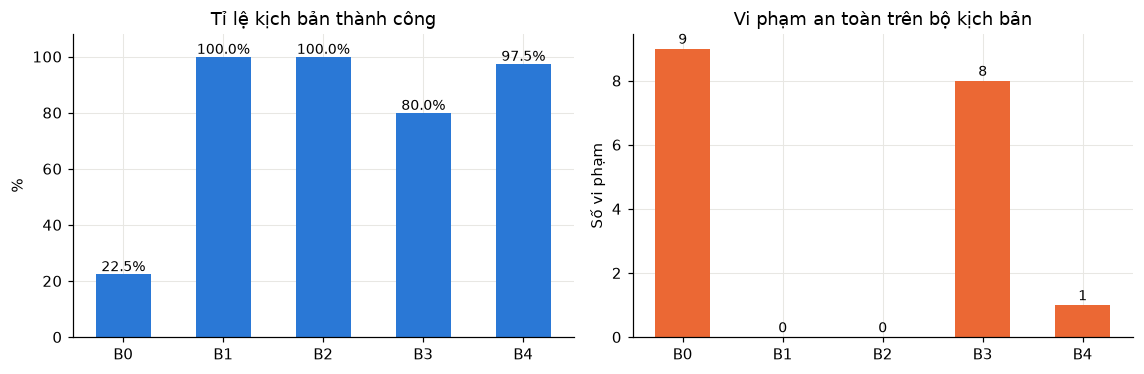

In [37]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.5))
names = [c.split()[0] for c in sys_results.index]
ax[0].bar(names, sys_results["Thành công"] * 100, color=BLUE, width=.55)
ax[1].bar(names, sys_results["Vi phạm"], color=ORANGE, width=.55)
ax[0].set(ylabel="%", ylim=(0, 108), title="Tỉ lệ kịch bản thành công")
ax[1].set(ylabel="Số vi phạm", title="Vi phạm an toàn trên bộ kịch bản")
for i, v in enumerate(sys_results["Thành công"]):
    ax[0].text(i, v * 100 + 1, f"{v * 100:.1f}%", ha="center", fontsize=9)
for i, v in enumerate(sys_results["Vi phạm"]):
    ax[1].text(i, v + .15, f"{int(v)}", ha="center", fontsize=9)
save(fig, "fig_system_eval")

## 10. Demo tương tác

Khi trình bày, nhập câu hỏi bất kỳ vào ô dưới rồi bấm **Gửi**. Hội thoại dùng chung một phiên nên hệ thống nhớ hồ sơ qua các lượt. Bấm **Phiên mới** để xóa bộ nhớ.

In [38]:
import ipywidgets as w
live = Coordinator()
box = w.Textarea(placeholder="Ví dụ: Nữ 45 tuổi, BMI 26, HbA1c 6,1%, đánh giá nguy cơ", layout=w.Layout(width="100%", height="70px"))
send, reset, out = w.Button(description="Gửi", button_style="primary"), w.Button(description="Phiên mới"), w.Output()
session = {"id": "live-0", "n": 0}

def on_send(_):
    with out:
        out.clear_output()
        if box.value.strip():
            report(live.ask(box.value, session["id"]), "Kết quả")

def on_reset(_):
    session["n"] += 1; session["id"] = f"live-{session['n']}"
    with out:
        out.clear_output(); print("Đã bắt đầu phiên mới")

send.on_click(on_send); reset.on_click(on_reset)
display(w.VBox([box, w.HBox([send, reset]), out]))

In [39]:
def consult(text, session="presentation"):
    """Gọi nhanh khi trình bày: consult('...')"""
    report(live.ask(text, session), "Kết quả")

json.dump({k: {x: v[x] for x in ("text", "path", "answer", "critic_rounds", "messages", "latency_ms")} for k, v in DEMO.items()}, open(RES / "demo_results.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
consult("Tiền tiểu đường cần xét nghiệm lại bao lâu một lần?")

### Kết quả
**1. Câu hỏi:** Tiền tiểu đường cần xét nghiệm lại bao lâu một lần?

**2. Luồng agent:** intake → safety → knowledge → advisor → safety

**3. Công cụ:** parse_profile, red_flags, critic, search_kb, compose

**4. Thông tin KG:**
- (Tiền đái tháo đường, tăng_nguy_cơ, Type 2) [T07]
- (Tiền đái tháo đường, có_thể_tiến_triển, Type 2) [N13]
- (Tiền đái tháo đường, đặc_trưng_bởi, Đường huyết cao hơn bình thường chưa đạt Type 2) [X07]
- (Đái tháo đường, đặc_trưng_bởi, Tăng đường huyết) [X01]

**5. Tài liệu truy xuất và bằng chứng:**
1. **N07** (web) Tần suất xét nghiệm lại: NIDDK
2. **T07** (web) Tiền đái tháo đường: NIDDK_TYPES
3. **X06** (web) Xét nghiệm dùng trong chẩn đoán: NIDDK

**6. Câu trả lời:**

Theo các nguồn đã truy xuất:

- Người có kết quả bình thường nên xét nghiệm lại sau mỗi 3 năm. Người được chẩn đoán tiền đái tháo đường nên xét nghiệm type 2 hằng năm. [1]

- Tiền đái tháo đường là đường huyết cao hơn bình thường nhưng chưa đạt mức đái tháo đường; tăng nguy cơ type 2. [2]

- Bác sĩ dùng xét nghiệm máu để chẩn đoán. HbA1c phản ánh đường huyết trung bình khoảng ba tháng; đường huyết đói đo tại một thời điểm. OGTT hỗ trợ phát hiện Type 2, tiền đái tháo đường và thai kỳ. Đường huyết ngẫu nhiên được dùng khi có triệu chứng. Máy đo tại nhà không đủ để chẩn đoán. [3]

Thông tin chỉ để tham khảo, không thay thế chẩn đoán của bác sĩ.

**7. Đánh giá nhanh:** mức an toàn `ok`, vòng Critic 0, tin nhắn 10, lỗi 0, thời gian 6 ms
